# GPT-2 small activation atlas: exploring stage 1

Reads the outputs of `python -m atlas` (see `docs/atlas-design.md`) and looks at what they say about GPT-2 small.
Build them first with `run-atlas`: 1M tokens, one 127-token window from each of ~8k documents across eight OpenWebText
files, run as 16 shards for bootstrap errors; about 5 minutes on an M4. §5 also needs
`run-atlas results/atlas-fineweb 1e6 fineweb` and `run-atlas results/atlas-code 1e6 code`, §6–§8 the deep scan, the
512-token atlas and the uncentered atlas described in `docs/results.md`.

1. Residual-stream geometry: how variance and effective dimension grow with depth
2. MLP neurons: firing rates and peak activations by layer
3. Single units: a neuron's histogram and top contexts; a residual dimension's top and bottom contexts
4. Errors: statistical (bootstrap over shards) and file to file (bootstrap over files)
5. Corpus systematic: OpenWebText vs FineWeb vs Python code
6. Deep scan of layers 0–2: rare and never-firing neurons over 50M tokens
7. Position and context length: statistics by position, up to 511 tokens
8. Dependence on centering the residual stream: centered (TransformerLens) vs raw
9. The gate into stage 2: does a pretrained SAE reproduce its release's metrics here?
10. Stage 2: the atlas in the SAE basis, layers 6 and 9
11. Stage 2: the IOI repair in the SAE basis
12. Validation checks

Figures are saved to `docs/figures/` for `docs/results.md`; run headless with `run-notebook`.

All statistics exclude position 0 (BOS) and are conditional on OpenWebText and positions 1–127.

In [1]:
import json
from pathlib import Path
from types import SimpleNamespace

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import torch
import pandas as pd
from atlas import HFGPT2, bootstrap_weights, pooled_moments

ATLAS = Path("../results/atlas")
FIGURES = Path("../docs/figures")  # figures for docs/results.md
manifest = json.loads((ATLAS / "manifest.json").read_text())
neurons = duckdb.sql(f"select * from '{ATLAS / 'neurons.parquet'}'").df()
topk = duckdb.sql(f"select * from '{ATLAS / 'topk.parquet'}'").df()
resid = np.load(ATLAS / "resid.npz")
hists = np.load(ATLAS / "histograms.npz")
tokens = np.load(ATLAS / "tokens.npy", mmap_mode="r")

# Categorical slots 1-4 and text inks of the dataviz default palette, as in the ioi-hydra notebook.
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e5e4df"
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

def tidy(ax):
    ax.grid(axis="y", color=GRID, zorder=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

print(f"{manifest['n_rows']:,} rows x {manifest['seq_len']} tokens from {manifest['n_docs']:,} documents "
      f"({manifest['dataset']} files {manifest['files']}, at most {manifest['max_windows_per_doc']} window per document)")
print(f"{neurons['n'].iloc[0]:,} tokens per unit; {len(neurons):,} units; {len(topk):,} top- and bottom-k exemplars")

7,816 rows x 128 tokens from 7,816 documents (owt files [0, 1, 2, 3, 4, 5, 6, 7], at most 1 window per document)
992,632 tokens per unit; 46,848 units; 1,136,640 top- and bottom-k exemplars


## 1. Residual-stream geometry

From the per-layer covariance in `resid.npz` ("layer 12" is the final residual stream, the input to `ln_final`).

- **Total variance**, the trace of the covariance: how much the stream's spread grows with depth.
- **Effective dimension**, the participation ratio $(\sum_i \lambda_i)^2 / \sum_i \lambda_i^2$ of the eigenvalues: about
  1 if one direction carries everything, 768 if variance is spread evenly.
- **Largest single basis dimension's share of variance**: the residual basis is not privileged in general, but GPT-2 is
  known to have a few outlier dimensions (447 among them).

*Expect:* variance growing roughly exponentially with depth, and a low effective dimension where outlier dimensions dominate.

layer  total var        eff. dim      dims for 90%  top basis dim (share)
    0      11.6 ± 0.0     14.3 ± 0.0            411   479 (2%)
    1    1033.2 ± 0.7     31.2 ± 0.0            314   480 (7%)
    2    1322.1 ± 0.8     46.2 ± 0.0            327   480 (7%)
    3    1662.8 ± 1.0     71.8 ± 0.1            378   480 (5%)
    4    2156.7 ± 1.2    104.0 ± 0.1            424   480 (4%)
    5    2667.8 ± 1.4    131.6 ± 0.2            450   480 (3%)
    6    3379.4 ± 1.9    151.0 ± 0.2            468   480 (3%)
    7    4339.8 ± 2.5    165.0 ± 0.2            485   480 (2%)
    8    5861.2 ± 4.4    170.7 ± 0.3            500   447 (2%)
    9    8109.2 ± 6.5    171.8 ± 0.3            507   447 (2%)
   10   11943.4 ± 9.4    157.6 ± 0.4            515   481 (2%)
   11   19070.0 ± 20.9   104.1 ± 0.5            510   496 (2%)
   12   56096.7 ± 198.9    6.8 ± 0.0            348   496 (11%)


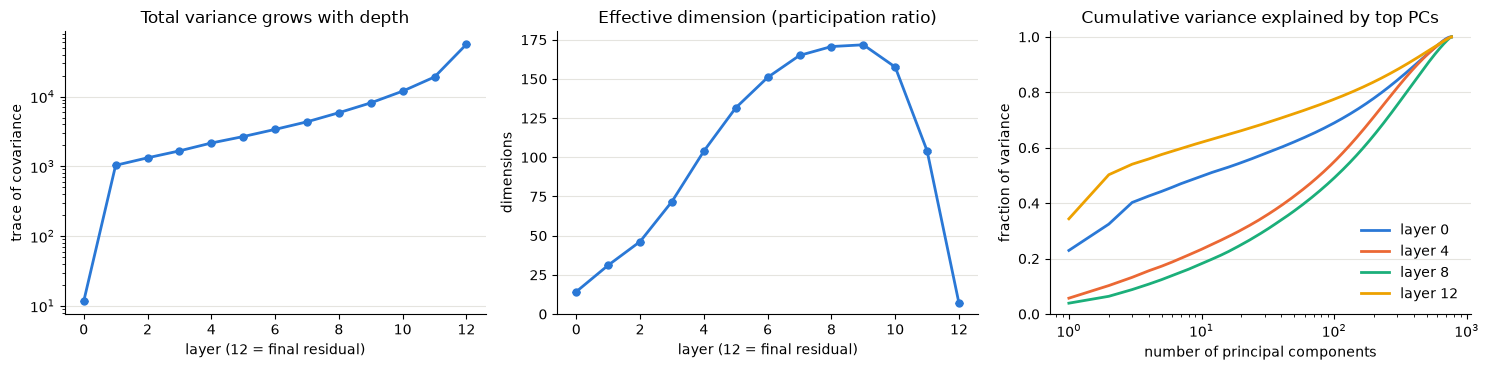

In [2]:
layers, cov = resid["layer"], resid["cov"]
eig = np.linalg.eigvalsh(cov)[:, ::-1]  # [13, 768], descending
total, pr = resid["total_var"], resid["pr"]  # = eig.sum(1) and eig.sum(1)**2 / (eig**2).sum(1)
total_err, pr_err = resid["total_var_err"], resid["pr_err"]  # bootstrap over shards
diag = np.diagonal(cov, axis1=1, axis2=2)
top_dim, top_share = diag.argmax(1), diag.max(1) / total
dims90 = (np.cumsum(eig, 1) / total[:, None] < 0.9).sum(1) + 1

print("layer  total var        eff. dim      dims for 90%  top basis dim (share)")
for l in layers:
    print(f"{l:5d}  {total[l]:8.1f} ± {total_err[l]:<5.1f}  {pr[l]:5.1f} ± {pr_err[l]:<4.1f}  {dims90[l]:12d}  {top_dim[l]:4d} ({top_share[l]:.0%})")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].errorbar(layers, total, yerr=total_err, fmt="o-", color=C[0], lw=2, ms=5, capsize=3)
axes[0].set(yscale="log", title="Total variance grows with depth", xlabel="layer (12 = final residual)", ylabel="trace of covariance")
axes[1].errorbar(layers, pr, yerr=pr_err, fmt="o-", color=C[0], lw=2, ms=5, capsize=3)
axes[1].set(title="Effective dimension (participation ratio)", xlabel="layer (12 = final residual)", ylabel="dimensions", ylim=(0, None))
for i, l in enumerate([0, 4, 8, 12]):
    axes[2].plot(np.arange(1, 769), np.cumsum(eig[l]) / total[l], color=C[i], lw=2, label=f"layer {l}")
axes[2].set(xscale="log", title="Cumulative variance explained by top PCs", xlabel="number of principal components", ylabel="fraction of variance", ylim=(0, 1.02))
axes[2].legend(frameon=False, loc="lower right")
for ax in axes:
    tidy(ax)
plt.tight_layout()
save(fig, "results_resid_geometry")

**Reading it.** The first block multiplies the stream's variance by about 90 (layer 0 is the embedding alone), and it
grows steadily after that, another 3× in the last block. The effective dimension rises from 14 to about 170 by layers
7–9, then collapses to about 7 at the final residual stream, where a handful of directions carry most of the variance
(the top principal component alone carries about a third). In the basis, dimension 480 stands out early (7.5% of the
variance at layer 1, falling to 2% by layer 7); from layer 7 to 11 no dimension carries more than about 2.5%, so which
one is largest there is not meaningful. At the final residual, dimensions 496, 430 and 36 carry 11%, 8% and 8%. The
bootstrap errors are tiny: the effective dimension is known to better than ±0.5 at every layer.

## 2. MLP neurons

Each neuron's firing rate (fraction of tokens with post-GELU activation > 0) and its peak activation, summarized per
layer as the median with a 10th–90th percentile band. Rarely-firing neurons are those with a firing rate below 1e-4,
fewer than about 100 tokens in 1M.

*Expect:* early layers to hold most of the rarely-firing neurons, and peak activations to grow in the last layers.

highest-peak neurons:
 layer  unit       max     mean      std  frac_pos      p999
    11  2378 57.170727 1.001086 5.359939  0.058272 47.904977
    10  2931 23.615377 0.277336 1.499259  0.065671 16.241357
    10  2114 20.820570 0.218521 1.779915  0.024499 17.088954
    11   584 17.666113 0.405993 1.946318  0.062475 14.895774
    11  3066 17.230169 0.366137 1.755176  0.098170 15.073311


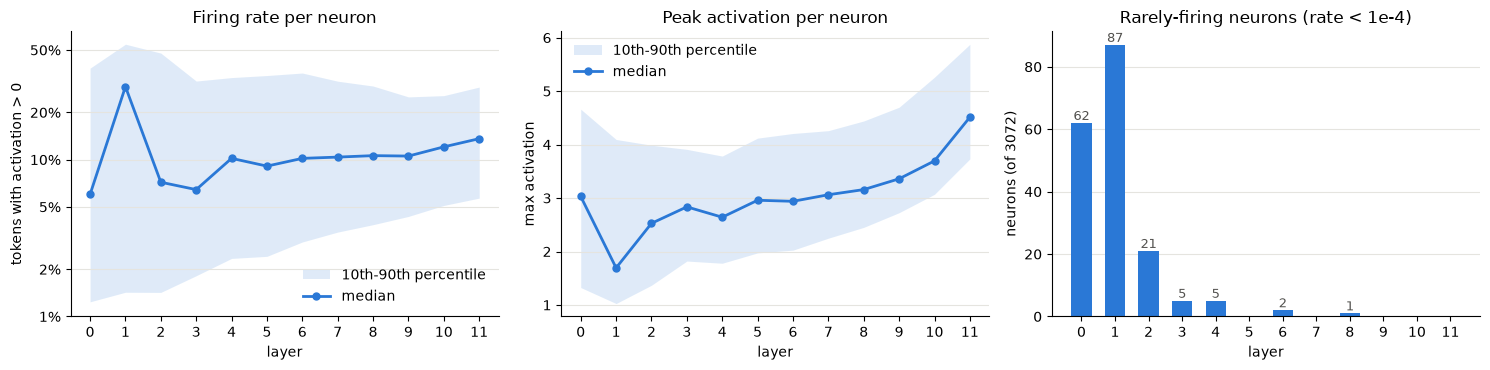

In [3]:
mlp = neurons[neurons.kind == "post"]
by = mlp.groupby("layer")
q = lambda col, p: by[col].quantile(p).to_numpy()
L = np.arange(12)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, title, ylabel, log in [
    (axes[0], "frac_pos", "Firing rate per neuron", "tokens with activation > 0", True),
    (axes[1], "max", "Peak activation per neuron", "max activation", False),
]:
    ax.fill_between(L, q(col, 0.1), q(col, 0.9), color=C[0], alpha=0.15, lw=0, label="10th-90th percentile")
    ax.plot(L, q(col, 0.5), "o-", color=C[0], lw=2, ms=5, label="median")
    ax.set(title=title, xlabel="layer", ylabel=ylabel, yscale="log" if log else "linear")
    if log:
        ax.set_yticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.5], ["1%", "2%", "5%", "10%", "20%", "50%"])
        ax.yaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
    ax.legend(frameon=False)
rare = by["frac_pos"].apply(lambda s: (s < 1e-4).sum()).to_numpy()
axes[2].bar(L, rare, color=C[0], width=0.6, zorder=2)
for l, n in zip(L, rare):
    if n:
        axes[2].text(l, n, str(n), ha="center", va="bottom", fontsize=9, color=INK2)
axes[2].set(title="Rarely-firing neurons (rate < 1e-4)", xlabel="layer", ylabel="neurons (of 3072)")
for ax in axes:
    ax.set_xticks(L)
    tidy(ax)
plt.tight_layout()
save(fig, "results_mlp_neurons")

print("highest-peak neurons:")
print(mlp.nlargest(5, "max")[["layer", "unit", "max", "mean", "std", "frac_pos", "p999"]].to_string(index=False))

**Reading it.** Layers 0–2 hold most of the rarely-firing neurons (61, 87 and 21 of 3072). Layer 1 is the odd one out:
its median neuron fires on about 30% of tokens, more than twice the median of any other layer. Peak activations climb steadily
through the last layers, and the highest-peak neurons are all in layers 10–11.

## 3. Single units

`show_neuron(layer, unit)` prints the neuron's summary row, plots its activation histogram (from `histograms.npz`, on
an asinh axis: linear near 0, logarithmic in the tails) and lists its top-activating contexts with the token marked «like this». For a residual dimension
(`hook="blocks.L.hook_resid_pre"`), which is signed, it also lists the bottom (most negative) contexts.

blocks.9.mlp.hook_post unit 1000: mean -0.081, std 0.146, max 3.24, fires on 7.9% of tokens, p50 -0.117, p99 0.62, p99.9 1.38


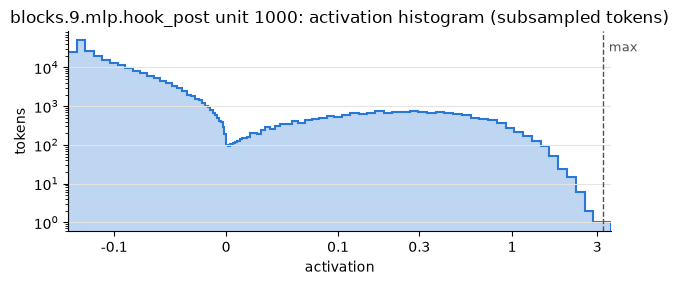

top contexts:
     3.24  human beings. Another definition describes eugenics as any one of« a» number of social and
     3.09   first of« a» string of attacks targeting
     2.97  ille, N.C.⏎⏎This event is free and open to the public.⏎⏎This is one of« a» series of free,
     2.85  d a multiple rocket launcher and thermobaric weapon. It is one of« a» spate of new weapons
     2.77  ouple of buckets of water and a headless effigy of the man she« has» accused of raping her
     2.77  eks ago, allowing transgender people to use the bathroom of« their» choice and the company
     2.73  nded clause will now read: “Parliament shall, by law, on« the» recommendation of the Goods
     2.72  The first of« a» series of four studies
     2.71  , reading, “In Case of the Removal of the President from Office, or of« his» Death, Resign
     2.69   THE CITY OF ST. LOUIS AS FOLLOWS: 5 SECTION ONE. Ordinance 40429«,» approved December 14,


In [4]:
EDGES = hists["edges"]

def show_neuron(layer, unit, n=10, hook=None, save_as=None):
    hook = hook or f"blocks.{layer}.mlp.hook_post"
    row = neurons[(neurons.hook == hook) & (neurons.unit == unit)].iloc[0]
    print(f"{hook} unit {unit}: mean {row['mean']:.3f}, std {row['std']:.3f}, max {row['max']:.2f}, "
          f"fires on {row.frac_pos:.1%} of tokens, p50 {row.p50:.3f}, p99 {row.p99:.2f}, p99.9 {row.p999:.2f}")
    counts = hists[hook][unit]
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.stairs(counts[1:-1], EDGES, color=C[0], lw=1.5, fill=True, alpha=0.3)
    ax.stairs(counts[1:-1], EDGES, color=C[0], lw=1.5)
    ax.axvline(row["max"], color=INK2, lw=1, ls="--")
    ax.annotate("max", (row["max"], 0.9), xycoords=("data", "axes fraction"), xytext=(4, 0), textcoords="offset points", fontsize=9, color=INK2)
    nz = np.nonzero(counts[1:-1])[0]
    lo, hi = EDGES[nz[0]], EDGES[nz[-1] + 1]
    ax.set_xscale("asinh", linear_width=0.05)
    ticks = [t for t in (-1, -0.1, 0, 0.1, 0.3, 1, 3, 10, 30, 100) if lo <= t <= hi]
    ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
    ax.xaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
    ax.set(yscale="log", xlim=(lo, hi),
           title=f"{hook} unit {unit}: activation histogram (subsampled tokens)", xlabel="activation", ylabel="tokens")
    tidy(ax)
    if save_as:
        save(fig, save_as)
    plt.show()
    for side in ("top", "bottom"):
        t = topk[(topk.hook == hook) & (topk.unit == unit) & (topk.side == side)].sort_values("rank").head(n)
        if len(t):
            print(f"{side} contexts:")
        for v, ctx in zip(t.value, t.context):
            print(f"  {v:7.2f}  {ctx[-90:]}")

show_neuron(9, 1000, save_as="results_neuron_l9_1000")

blocks.11.mlp.hook_post unit 2378: mean 1.001, std 5.360, max 57.17, fires on 5.8% of tokens, p50 -0.001, p99 37.16, p99.9 47.90


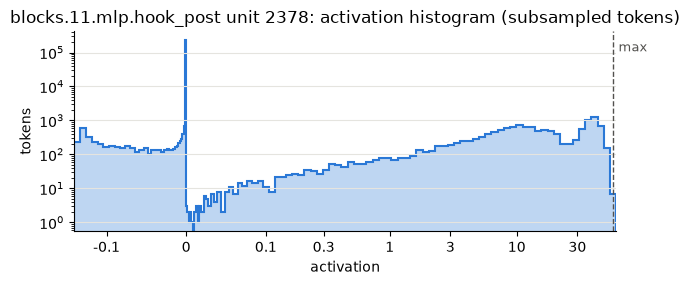

top contexts:
    57.17  ⏎"What he is proposing would leave Wales worse off, and we cannot accept that.«⏎»⏎"We know
    56.92   are bitter, removed, so even a dark-looking chocolate can have no flavanol.«⏎»⏎"Consumers
    55.85  nimation cut scenes)⏎⏎- more info on item screen⏎⏎- trinkets on item screen«⏎»⏎- export is
    55.79  done on the individual side with items that do not generate economic growth.«⏎»⏎"But after
    55.65  d address the fair funding issue, and now he appears to be going back on that.«⏎»⏎"What he
    55.60   they feel it."⏎⏎Sky Blues boss Tony Mowbray told BBC Coventry & Warwickshire:«⏎»⏎"It was
    55.20  s did nothing about the racist chants from our fans towards Bradford City y'day?«⏎»⏎"Clubs
    55.02  If you paid your money to come and watch, you weren't getting your money's worth.«⏎»⏎"Scun
    54.89  st week when Nigel Farage announced he was standing down.⏎⏎'Head held high'«⏎»⏎He said his
    54.87  or mentally ill Nova Scotia man who killed his mother, gra

In [5]:
# The neuron with the largest peak activation in the last layer.
l11 = mlp[mlp.layer == 11].nlargest(1, "max").iloc[0]
show_neuron(11, int(l11.unit), save_as="results_neuron_l11_peak")

**A residual dimension.** Residual dimensions are signed, so the atlas keeps both extremes. Dimension 447 is the
basis dimension with the largest share of variance in layers 8–10 (§1); here it is at the input to layer 9.

blocks.9.hook_resid_pre unit 447: mean 49.318, std 12.021, max 104.19, fires on 99.9% of tokens, p50 50.219, p99 75.54, p99.9 84.71


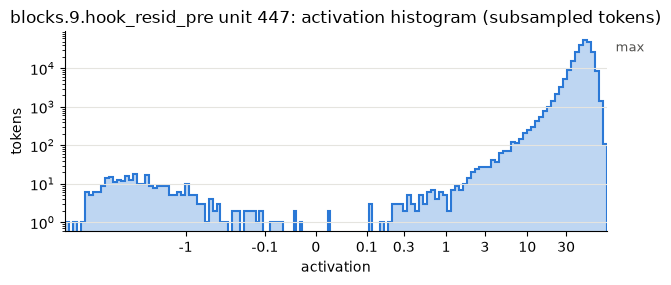

top contexts:
   104.19   by helping you to define your system as function.⏎⏎In nutshell,« Su»ave complements Azure
   100.68  I have gotten together to offer commission slots for bidding to raise money for« Bind»i.⏎⏎
   100.52  tions, and it will return to you a java model object. By default,« Retro»fit does the JSON
    99.19  ctive game rather than a first-person shooter. This probably means« Hus»k will combine its
    98.67  nful, and they seemed unavoidable when returning to nostalgic locations.« Cron»o snickered
    97.83   The« spiders» are roughly the size
    96.81  0(GetX, int ()); MOCK_CONST_METHOD0(GetY, int ()); }; class« Painter» { Turtle* turtle
    96.78  ner’s, and for that matter, your, watch. This presents serious issues regarding« Con»ner’s
    96.72  ⏎TextExpander⏎⏎With the launch of iOS 8,« Text»Expander will be
    96.50  og post written by Vince Sollitto, a company spokesman:⏎⏎One thing« Rev»leap actually does
bottom contexts:
   -29.85  olicy here. Sign up for 

In [6]:
show_neuron(9, 447, hook="blocks.9.hook_resid_pre", save_as="results_resid_l9_447")

## 4. Errors: statistical and file to file

`export` gives two bootstrap errors on every unit's mean, std and firing rate, and on each layer's total variance and
effective dimension (§1):

- `*_err_stat` resamples the 16 shards with replacement within each OpenWebText file: statistical noise.
- `*_err`, the total error, resamples the 8 files instead, each drawn file bringing its shards (a cluster bootstrap).
  It also covers the variation from one file of the corpus to the next. Resampling the shards inside each drawn file
  too would count the within-file noise twice.

Both are corrected for the few resampling units: a bootstrap over G units underestimates the variance by (G − 1) / G,
which with 2 shards per file would make `*_err_stat` √2 too small. Whole shards are the resampling unit, so
correlations between rows within a shard are accounted for.

**The file-to-file term.** Files of one corpus are not perfect replicates. For each unit, compare the observed variance
of its 8 file means with the variance expected from noise alone, estimated from the scatter of each file's 2 shards.
Their ratio follows an F(7, 8) distribution if files differ only by noise; the excess is the file-to-file variance.

median error                       MLP neurons (total / stat)   residual dims (total / stat)
  on the mean, in units of std        0.0021 / 0.0021             0.0025 / 0.0024
  on the std, relative                0.0054 / 0.0053             0.0012 / 0.0011
  on the firing rate, relative        0.0068 / 0.0065             0.0022 / 0.0021



8 files x 2 shards

observed / noise variance of file means   median (null 0.99)   above null's 95th pct (null 0.05)   file-to-file std / unit std
  MLP neurons: mean                              1.06                       0.06                     0.0013
  residual dims: mean                            1.06                       0.06                     0.0015
  MLP neurons: firing rate                       1.08                       0.06                     0.0016



effective dimension: total error, statistical error, and the spread over files
layer   eff. dim   err (total)   err_stat   min-max over files
    0       14.3          0.01       0.01     14.2 - 14.3
    1       31.2          0.02       0.02     31.1 - 31.2
    2       46.2          0.04       0.03     46.1 - 46.4
    3       71.8          0.07       0.06     71.5 - 72.1
    4      104.0          0.14       0.12    103.3 - 104.5
    5      131.6          0.16       0.19    130.8 - 132.1
    6      151.0          0.22       0.28    149.8 - 151.9
    7      165.0          0.25       0.37    163.5 - 165.7
    8      170.7          0.30       0.42    168.6 - 171.1
    9      171.8          0.32       0.37    169.7 - 172.1
   10      157.6          0.37       0.38    155.4 - 158.1
   11      104.1          0.49       0.35    102.3 - 105.9
   12        6.8          0.04       0.04      6.7 - 7.0


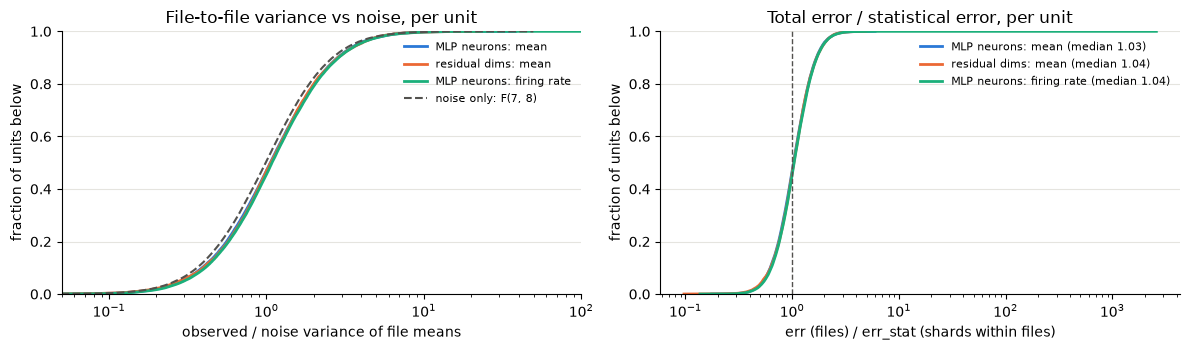

In [7]:
mlp_mask = (neurons.kind == "post").to_numpy()
print("median error                       MLP neurons (total / stat)   residual dims (total / stat)")
for label, col, scale in [("on the mean, in units of std", "mean", neurons["std"]), ("on the std, relative", "std", neurons["std"]),
                          ("on the firing rate, relative", "frac_pos", neurons.frac_pos.where(neurons.frac_pos > 0))]:
    tot, stat = neurons[f"{col}_err"] / scale, neurons[f"{col}_err_stat"] / scale
    print(f"  {label:32s} {np.nanmedian(tot[mlp_mask]):9.4f} / {np.nanmedian(stat[mlp_mask]):<9.4f}"
          f"       {np.nanmedian(tot[~mlp_mask]):9.4f} / {np.nanmedian(stat[~mlp_mask]):.4f}")

# Per-shard moments, in the same unit order as `neurons`.
sh = pd.read_parquet(ATLAS / "shards.parquet")
S, U = sh.shard.nunique(), len(neurons)
assert (sh.hook.to_numpy()[:U] == neurons.hook.to_numpy()).all() and (sh.unit.to_numpy()[:U] == neurons.unit.to_numpy()).all()
arr = lambda col: sh[col].to_numpy().reshape(S, U)
n_s, files_s = arr("n")[:, 0], arr("file")[:, 0]
moments_s = (n_s, arr("mean"), arr("m2"), arr("n_pos"))
pool = lambda mask: pooled_moments(np.asarray(mask, float)[None], *moments_s)
files = np.unique(files_s)
F, k = len(files), S // len(files)  # files, shards per file
print(f"\n{F} files x {k} shards")

def file_components(shards_df, F, k):
    """Per unit: observed variance of the F file means, and the variance expected from noise alone (the scatter of
    each file's k shards / k). Returns {key: (ratio, observed - noise, noise)} for the mean and the firing rate."""
    S_, U_ = F * k, len(shards_df) // (F * k)
    a_ = lambda col: shards_df[col].to_numpy().reshape(S_, U_)
    out = {}
    for key, per_shard in [("mean", a_("mean")), ("frac_pos", a_("n_pos") / a_("n"))]:
        by_file = per_shard.reshape(F, k, U_)
        noise = (by_file.var(1, ddof=1) / k).mean(0)
        observed = by_file.mean(1).var(0, ddof=1)
        with np.errstate(divide="ignore", invalid="ignore"):
            out[key] = SimpleNamespace(ratio=observed / noise, sigma2_file=observed - noise, noise=noise)
    return out

comp = file_components(sh, F, k)
null = np.random.default_rng(0).f(F - 1, F * (k - 1), 200_000)

PANELS = [("mean", mlp_mask, "MLP neurons: mean"), ("mean", ~mlp_mask, "residual dims: mean"),
          ("frac_pos", mlp_mask, "MLP neurons: firing rate")]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
print(f"\nobserved / noise variance of file means   median (null {np.median(null):.2f})   above null's 95th pct (null 0.05)"
      "   file-to-file std / unit std")
for i, (key, m, label) in enumerate(PANELS):
    c = comp[key]
    r = c.ratio[m & np.isfinite(c.ratio)]
    spread = neurons["std"].to_numpy() if key == "mean" else np.sqrt(neurons.frac_pos * (1 - neurons.frac_pos)).to_numpy()
    with np.errstate(divide="ignore", invalid="ignore"):
        s2 = c.sigma2_file[m] / spread[m] ** 2
    print(f"  {label:38s} {np.median(r):12.2f}   {np.mean(r > np.quantile(null, 0.95)):24.2f}"
          f"   {np.sqrt(max(np.nanmedian(s2), 0)):24.4f}")
    v = np.sort(r)
    axes[0].plot(v, np.arange(1, len(v) + 1) / len(v), color=C[i], lw=2, label=label)
v = np.sort(null)
axes[0].plot(v, np.arange(1, len(v) + 1) / len(v), color=INK2, lw=1.5, ls="--", label=f"noise only: F({F - 1}, {F * (k - 1)})")
axes[0].set(xscale="log", xlim=(0.05, 100), ylim=(0, 1), title="File-to-file variance vs noise, per unit",
            xlabel="observed / noise variance of file means", ylabel="fraction of units below")
axes[0].legend(frameon=False, fontsize=8)
for i, (col, m, label) in enumerate(PANELS):
    r = (neurons[f"{col}_err"] / neurons[f"{col}_err_stat"]).to_numpy()[m]
    v = np.sort(r[np.isfinite(r)])
    axes[1].plot(v, np.arange(1, len(v) + 1) / len(v), color=C[i], lw=2, label=f"{label} (median {np.median(v):.2f})")
axes[1].axvline(1, color=INK2, lw=1, ls="--")
axes[1].set(xscale="log", ylim=(0, 1), title="Total error / statistical error, per unit",
            xlabel="err (files) / err_stat (shards within files)", ylabel="fraction of units below")
axes[1].legend(frameon=False, fontsize=8)
for ax in axes:
    tidy(ax)
plt.tight_layout()
save(fig, "results_corpus_check")

print("\neffective dimension: total error, statistical error, and the spread over files")
print("layer   eff. dim   err (total)   err_stat   min-max over files")
for l in layers:
    pf = resid["pr_file"][l]
    print(f"{l:5d}  {pr[l]:9.1f}  {resid['pr_err'][l]:12.2f}  {resid['pr_err_stat'][l]:9.2f}   {pf.min():6.1f} - {pf.max():.1f}")

**Reading it.** At 1M tokens over 8 files, the total error and the statistical error agree to within about 5% (for a
neuron's mean, 0.0021 of its spread for both). The file means scatter a little more than noise predicts (median ratio
1.06–1.08 against 0.99), which would put the file-to-file std near 0.0013–0.0016 of a unit's spread. That estimate is
weak, though: each file holds under 1k documents here, so its mean carries a noise of about 0.005, and all 36k units
share the same 8 files, so they are not independent tests. The 50M-token deep scan in §6, which reads about half of
the documents in the same 8 files, measures the term directly and finds it 5–10× smaller. The two errors still
differ in what they protect against: with many tokens from few files, the file term would dominate, and `*_err`
includes it.

## 5. Corpus systematic: OpenWebText vs FineWeb vs Python code

Every number above is conditional on OpenWebText. The same pipeline, sampling and 1M-token budget run on two more
corpora: **FineWeb** (sample-10BT; filtered Common Crawl, web text like OpenWebText but a different selection) and
**Python code** (codeparrot-clean, from GitHub), a deliberately different distribution.

**Per-unit shift.** For each unit, |mean on corpus X − mean on OpenWebText| in units of the unit's spread on
OpenWebText, compared with a *within-corpus floor*: the same quantity between two halves of OpenWebText (files 0–3 vs
4–7), scaled by 1/√2 because each half holds half the data (statistical noise plus the file-to-file term of §4). A curve to the
right of the floor is a corpus dependence beyond that. Firing rates are
compared as |log₁₀ ratio|.

*Expect:* FineWeb close to OpenWebText but above the floor; code far from both.

OpenWebText    Skylion007/openwebtext ['plain_text/train-00000-of-00080.parquet', 'plain_text/train-00001-of-00080.parquet', 'plain_text/train-00002-of-00080.parquet', 'plain_text/train-00003-of-00080.parquet', 'plain_text/train-00004-of-00080.parquet', 'plain_text/train-00005-of-00080.parquet', 'plain_text/train-00006-of-00080.parquet', 'plain_text/train-00007-of-00080.parquet']
FineWeb        HuggingFaceFW/fineweb ['sample/10BT/000_00000.parquet', 'sample/10BT/001_00000.parquet']
code (Python)  codeparrot/codeparrot-clean ['default/partial-train/0000.parquet', 'default/partial-train/0001.parquet']

median shift (× within-OWT floor)                FineWeb         code (Python)   floor
  MLP neurons: mean shift               0.028 (   14×)       0.172 (   85×)       0.0020
  Residual dims: mean shift             0.037 (   16×)       0.263 (  113×)       0.0023
  MLP neurons: firing-rate shift        0.045 (   18×)       0.335 (  133×)       0.0025


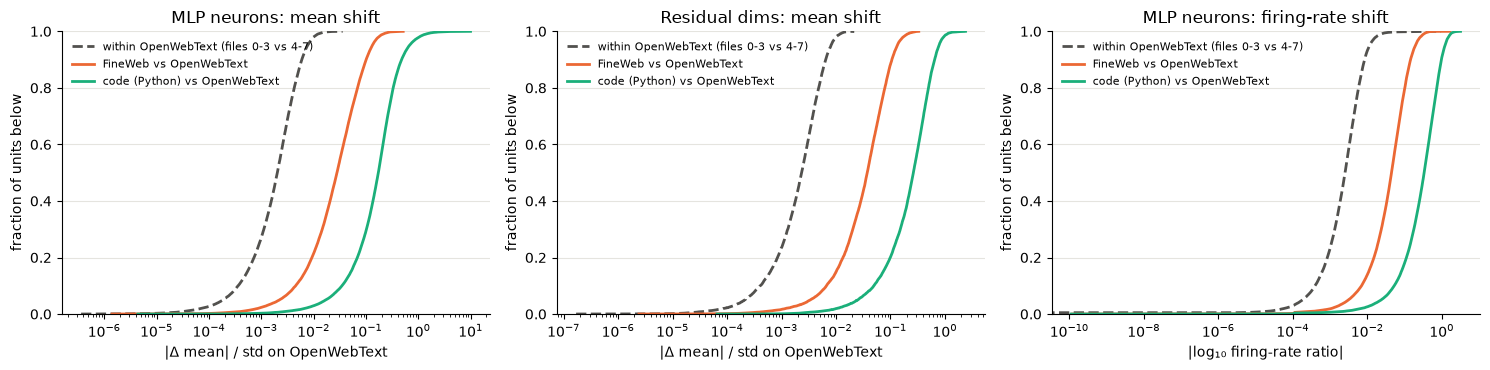

In [8]:
CORPORA = {"OpenWebText": ATLAS, "FineWeb": Path("../results/atlas-fineweb"), "code (Python)": Path("../results/atlas-code")}
corp = {}
for name, path in CORPORA.items():
    n_ = duckdb.sql(f"select * from '{path / 'neurons.parquet'}'").df()
    assert (n_.hook.to_numpy() == neurons.hook.to_numpy()).all() and (n_.unit.to_numpy() == neurons.unit.to_numpy()).all()
    corp[name] = SimpleNamespace(neurons=n_, resid=np.load(path / "resid.npz"), manifest=json.loads((path / "manifest.json").read_text()))
    print(f"{name:14s} {corp[name].manifest['repo']} {corp[name].manifest['paths']}")

owt = corp["OpenWebText"].neurons
sd = owt["std"].to_numpy()
smooth = lambda frac, n: (frac * n + 1) / (n + 2)  # firing rates with a pseudo-count, so log ratios stay finite
log_fr = lambda nn: np.log10(smooth(nn.frac_pos.to_numpy(), nn.n.to_numpy()))
# Within-OpenWebText floor: files 0-3 vs 4-7 (pooled from shards.parquet, §4), scaled to full-size samples.
half = np.isin(files_s, files[: F // 2])
p0, p1 = pool(half), pool(~half)
n_file = n_s[half].sum()
floor = {"mean": np.abs(p0["mean"][0] - p1["mean"][0]) / sd / np.sqrt(2),
         "fr": np.abs(np.log10(smooth(p0["frac_pos"][0], n_file)) - np.log10(smooth(p1["frac_pos"][0], n_file))) / np.sqrt(2)}
shift = {name: {"mean": np.abs(c.neurons["mean"].to_numpy() - owt["mean"].to_numpy()) / sd,
                "fr": np.abs(log_fr(c.neurons) - log_fr(owt))} for name, c in corp.items() if name != "OpenWebText"}

panels = [("mean", mlp_mask, "MLP neurons: mean shift", "|Δ mean| / std on OpenWebText"),
          ("mean", ~mlp_mask, "Residual dims: mean shift", "|Δ mean| / std on OpenWebText"),
          ("fr", mlp_mask, "MLP neurons: firing-rate shift", "|log₁₀ firing-rate ratio|")]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
print("\nmedian shift (× within-OWT floor) " + "".join(f"{n:>22s}" for n in shift) + "   floor")
for ax, (key, m, title, xlabel) in zip(axes, panels):
    for vals, color, ls, label in [(floor[key], INK2, "--", f"within OpenWebText (files {files[0]}-{files[F // 2 - 1]} vs {files[F // 2]}-{files[-1]})")] + \
            [(shift[n][key], C[i + 1], "-", f"{n} vs OpenWebText") for i, n in enumerate(shift)]:
        v = np.sort(vals[m & np.isfinite(vals)])
        ax.plot(v, np.arange(1, len(v) + 1) / len(v), color=color, ls=ls, lw=2, label=label)
    ax.set(xscale="log", ylim=(0, 1), title=title, xlabel=xlabel, ylabel="fraction of units below")
    ax.legend(frameon=False, fontsize=8)
    tidy(ax)
    fl = np.nanmedian(floor[key][m])
    print(f"  {title:31s}" + "".join(f"{np.nanmedian(shift[n][key][m]):12.3f} ({np.nanmedian(shift[n][key][m]) / fl:5.0f}×)" for n in shift) + f"   {fl:10.4f}")
plt.tight_layout()
save(fig, "results_corpus_units")

**Per-layer summaries.** Residual-stream total variance and effective dimension (from each corpus's covariance), and
the median MLP neuron's firing rate, by layer.

layer      OpenWebText eff. dim        FineWeb eff. dim  code (Python) eff. dim
    0               14.3 ± 0.0              14.7 ± 0.0              11.7 ± 0.0 
    1               31.2 ± 0.0              31.4 ± 0.0              14.2 ± 0.1 
    2               46.2 ± 0.0              46.3 ± 0.0              17.5 ± 0.1 
    3               71.8 ± 0.1              72.0 ± 0.1              18.0 ± 0.1 
    4              104.0 ± 0.1             105.7 ± 0.1              19.1 ± 0.1 
    5              131.6 ± 0.2             134.4 ± 0.1              24.2 ± 0.1 
    6              151.0 ± 0.2             156.3 ± 0.2              24.9 ± 0.2 
    7              165.0 ± 0.2             172.8 ± 0.3              26.2 ± 0.2 
    8              170.7 ± 0.3             179.7 ± 0.3              24.7 ± 0.2 
    9              171.8 ± 0.3             183.4 ± 0.3              27.1 ± 0.2 
   10              157.6 ± 0.4             171.0 ± 0.2              28.8 ± 0.2 
   11              104.1 ± 0.5          

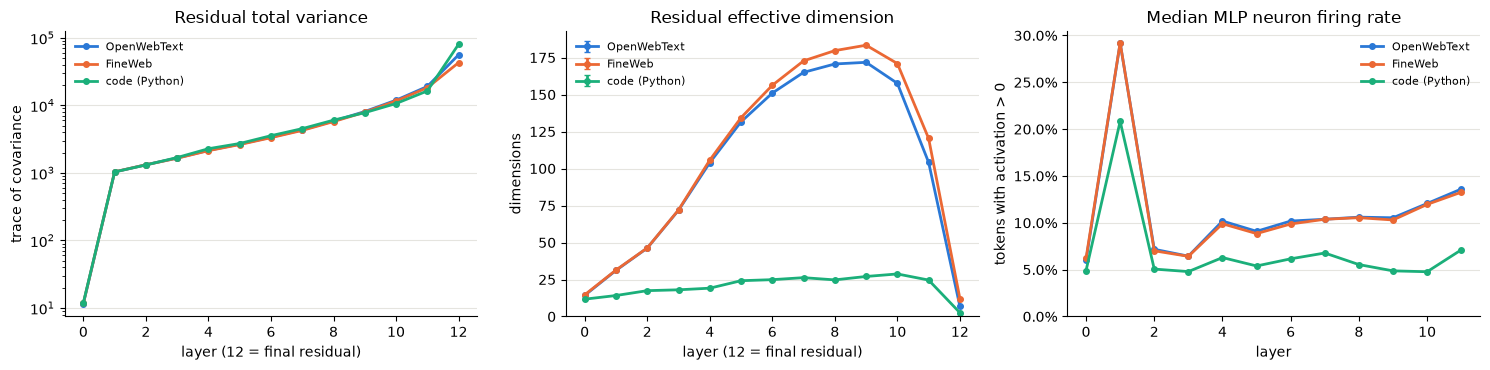

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for i, (name, c) in enumerate(corp.items()):
    r = c.resid
    axes[0].plot(r["layer"], r["total_var"], "o-", color=C[i], lw=2, ms=4, label=name)
    axes[1].errorbar(r["layer"], r["pr"], yerr=r["pr_err"], fmt="o-", color=C[i], lw=2, ms=4, capsize=2, label=name)
    fr = c.neurons[c.neurons.kind == "post"].groupby("layer").frac_pos.median()
    axes[2].plot(fr.index, fr.to_numpy(), "o-", color=C[i], lw=2, ms=4, label=name)
axes[0].set(yscale="log", title="Residual total variance", xlabel="layer (12 = final residual)", ylabel="trace of covariance")
axes[1].set(title="Residual effective dimension", xlabel="layer (12 = final residual)", ylabel="dimensions", ylim=(0, None))
axes[2].set(title="Median MLP neuron firing rate", xlabel="layer", ylabel="tokens with activation > 0", ylim=(0, None))
axes[2].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
    tidy(ax)
plt.tight_layout()
save(fig, "results_corpus_layers")

print("layer  " + "".join(f"{n + ' eff. dim':>24s}" for n in corp))
for l in corp["OpenWebText"].resid["layer"]:
    print(f"{l:5d}  " + "".join(f"{c.resid['pr'][l]:17.1f} ± {c.resid['pr_err'][l]:<4.1f}" for c in corp.values()))

**Offset dimensions.** The near-constant residual dimensions found in `docs/results.md` (§2 there): mean ± std
over tokens, per corpus.

In [10]:
OFFSET_DIMS, OFFSET_LAYERS = [64, 266, 326, 373, 447, 481], [1, 6, 11, 12]
res_of = lambda nn: nn[nn.kind == "resid"].set_index(["layer", "unit"])
print("dim  layer  " + "".join(f"{n:>22s}" for n in corp))
for dim in OFFSET_DIMS:
    for l in OFFSET_LAYERS:
        print(f"{dim:3d}  {l:5d}  " + "".join(f"{r.loc[(l, dim), 'mean']:12.1f} ± {r.loc[(l, dim), 'std']:<7.1f}"
                                          for r in map(res_of, (c.neurons for c in corp.values()))))

dim  layer             OpenWebText               FineWeb         code (Python)
 64      1         -23.7 ± 2.0           -23.7 ± 1.9           -23.3 ± 1.9    
 64      6         -27.2 ± 2.2           -27.3 ± 2.2           -28.1 ± 2.3    
 64     11         -28.1 ± 2.2           -28.2 ± 2.2           -28.3 ± 2.2    
 64     12        -118.9 ± 35.2         -124.5 ± 31.0         -108.3 ± 54.8   
266      1          11.3 ± 2.5            11.3 ± 2.5            11.5 ± 2.4    
266      6          11.7 ± 2.4            11.8 ± 2.4            12.8 ± 2.5    
266     11          11.9 ± 2.7            12.0 ± 2.7            13.1 ± 2.8    
266     12        -105.9 ± 38.9         -112.0 ± 35.3          -97.8 ± 60.6   
326      1           9.3 ± 1.7             9.6 ± 1.7            10.6 ± 1.5    
326      6          10.5 ± 2.4            11.2 ± 2.5            13.3 ± 1.9    
326     11          11.7 ± 4.9            13.2 ± 5.1            19.8 ± 5.8    
326     12          12.2 ± 10.2           14.4 ± 10.

373      1         -16.2 ± 4.0           -16.1 ± 4.0           -13.9 ± 4.0    
373      6         -21.3 ± 4.6           -21.5 ± 4.5           -19.8 ± 4.7    
373     11         -93.8 ± 17.9          -94.8 ± 16.0          -88.6 ± 21.9   
373     12        -143.0 ± 39.1         -149.4 ± 32.4         -129.2 ± 62.1   
447      1          17.3 ± 4.4            17.1 ± 4.4            15.0 ± 4.2    
447      6          32.0 ± 8.0            31.9 ± 7.7            30.2 ± 7.8    
447     11          89.4 ± 17.6           89.6 ± 16.0           82.1 ± 22.0   
447     12         127.5 ± 38.8          132.8 ± 34.2          123.0 ± 65.0   
481      1           0.4 ± 1.0             0.4 ± 1.0             0.4 ± 0.9    
481      6           6.4 ± 5.5             6.2 ± 5.3             6.8 ± 4.8    
481     11          92.8 ± 18.8           93.1 ± 17.0           88.5 ± 22.1   
481     12         133.3 ± 38.7          138.6 ± 33.2          124.2 ± 60.8   


**Neurons that change most on code.** The MLP neurons with the largest firing-rate ratio between code and OpenWebText,
each way, with their top context on code.

In [11]:
code_topk = duckdb.sql(f"select * from '{CORPORA['code (Python)'] / 'topk.parquet'}' where kind = 'post' and rank = 0").df().set_index(["layer", "unit"])
cn = corp["code (Python)"].neurons
ratio = log_fr(cn) - log_fr(owt)
frame = owt.assign(fr_owt=owt.frac_pos, fr_code=cn.frac_pos, log_ratio=ratio)[mlp_mask]
for label, rows in [("fire much more on code", frame.nlargest(6, "log_ratio")), ("fire much less on code", frame.nsmallest(4, "log_ratio"))]:
    print(f"{label}:")
    for r in rows.itertuples():
        ctx = code_topk.loc[(r.layer, r.unit), "context"][-70:]
        print(f"  L{r.layer:<2d} {r.unit:4d}  OWT {r.fr_owt:7.2%}  code {r.fr_code:7.2%}  top on code: {ctx!r}")

fire much more on code:
  L0  2469  OWT   0.04%  code  30.10%  top on code: '.⏎⏎« »   If randomly'
  L0  1889  OWT   0.01%  code   9.59%  top on code: '    for s in r:⏎               « i» += 1⏎ '
  L0  2489  OWT   0.00%  code   0.29%  top on code: 'art = True, fnc=boundFunction(main, plugin=x)))⏎⏎«\t»return pluginlist⏎'
  L0  1774  OWT   0.00%  code   0.43%  top on code: '3,4,6,7,8,9]]⏎⏎\tprint("Testing for family: GAMMA")⏎«\t»print'
  L1  1323  OWT   0.06%  code  12.83%  top on code: '       print "\\t\\t\\t\\t\\t\\t\\t\\t\\«t»'
  L1  2814  OWT   0.00%  code   0.07%  top on code: '\t\t\t\t\t\t\tpass⏎⏎\t\t\t\t\treturn output⏎⏎«\t»\t\t\tcheck'
fire much less on code:
  L5  1707  OWT   1.65%  code   0.00%  top on code: " '« +» str( results['"
  L4   961  OWT   9.59%  code   0.01%  top on code: 'ING N«EG»LIGENCE OR'
  L11 2652  OWT   5.38%  code   0.01%  top on code: '== Heaviside(x)⏎    assert conjugate(Heaviside(x - y))« ==» Heaviside('
  L5  1139  OWT   1.67%  code   0.00%  top on code

**Reading it.** FineWeb moves a typical unit 12–15× further than OpenWebText's two files differ from each other; code
moves it 77–117× further. The per-layer picture explains where. FineWeb follows OpenWebText closely but keeps a higher
effective dimension from layer 7 on (183 against 171 at layer 9, 12 against 7 at the final residual). Code differs
from the first block: its effective dimension stays near 25 at every layer, its neurons fire less (median 5–7% after
layer 1, 21% in layer 1), and its total variance at the final residual is 42% higher (FineWeb's is 24% lower). A likely cause is code's token
statistics: 37% of its tokens are pure whitespace (indentation) against 2–4% for web text, and its ten most common
token types cover half of all tokens, so a few directions carry much of the variance. The same residual dimensions are
offsets on all three corpora, with similar means through layer 11 (FineWeb within 4% of OpenWebText, code within
4–17%, except dimension 326, up to 14% and 70% larger), and the rarely-firing neurons are mostly the same neurons (168 rare on every corpus; 109 never fire on any of the 3M tokens), so both look like
properties of the model rather than of the data. A few early neurons are code-specific, nearly silent on web text
and firing on indentation and tabs.

## 6. Deep scan of layers 0–2: rare and never-firing neurons

The atlases above see 1M tokens per corpus, too few to tell a neuron that fires once in 10⁷ tokens from one that never
fires. The deep scan runs only layers 0–2, where almost all the rarely-firing neurons are (§2), over 50M OpenWebText
tokens: 390k documents from files 0–7, one window each, 50× the atlas. The forward pass stops after layer 2.

It records the MLP **pre**-activation (`mlp.hook_pre`), not the post-GELU value. GELU keeps the sign, so the firing
rate (fraction > 0) is the same, but the pre-activation also says how far a silent neuron stays from firing: its
maximum over 50M tokens, and the top-k contexts that come closest.

    python -m atlas tokenize results/deepscan-owt --n-tokens 5e7 --files 0,1,2,3,4,5,6,7
    python -m atlas run results/deepscan-owt --shards 16 --hooks 'blocks.[0-2].mlp.hook_pre'
    python -m atlas export results/deepscan-owt

The candidates are the neurons that never fired on any of the three 1M-token corpora (§5).

deep scan: 49,610,264 tokens per unit from 390,632 documents (owt files [0, 1, 2, 3, 4, 5, 6, 7])
never fired on 3 x 1M tokens: 110 neurons; 100 in layers 0-2, scanned here

layer  candidates  fire in 50M  still never   (rate bound if never: < 3 / 50M = 6e-8, 95% CL)
    0          29            4           25
    1          58            4           54
    2          13            3           10

those that fire: 11, firing on 2-39 of 50M tokens (median 15)
rare in the 1M atlas (58 neurons in layers 0-2): median firing tokens 10 in 1M, 512 in the 50M deep scan
neurons firing on > 0.1% of tokens: deep / atlas firing-rate ratio, median 1.000, 1st-99th pct 0.97-1.03


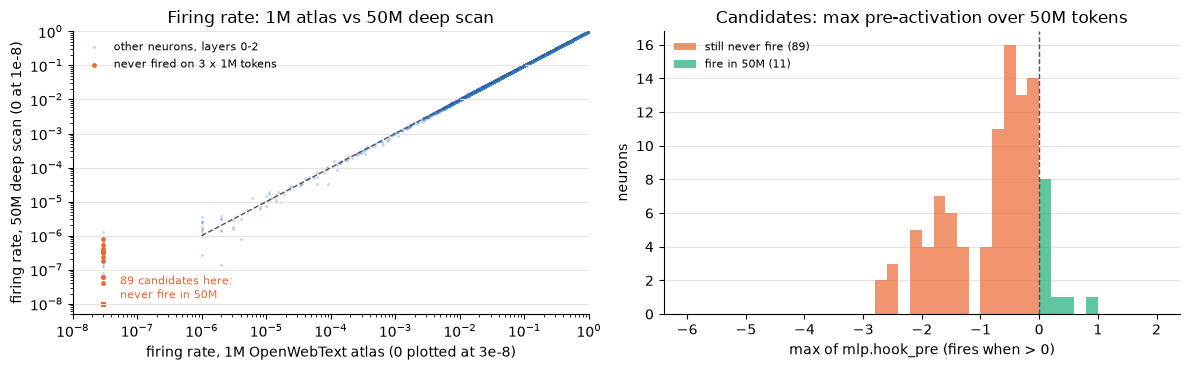

In [12]:
DEEP = Path("../results/deepscan-owt")
deep = duckdb.sql(f"select * from '{DEEP / 'neurons.parquet'}'").df().set_index(["layer", "unit"])
deep_topk = duckdb.sql(f"select * from '{DEEP / 'topk.parquet'}'").df()
dman = json.loads((DEEP / "manifest.json").read_text())
deep["fires"] = np.rint(deep.frac_pos * deep.n).astype(int)
print(f"deep scan: {deep.n.iloc[0]:,} tokens per unit from {dman['n_docs']:,} documents ({dman['dataset']} files {dman['files']})")

post = {name: c.neurons[c.neurons.kind == "post"].set_index(["layer", "unit"]) for name, c in corp.items()}
never_all = np.logical_and.reduce([p.frac_pos.to_numpy() == 0 for p in post.values()])
cand = post["OpenWebText"].index[never_all]
scanned = cand[cand.get_level_values("layer") <= 2]
dc = deep.loc[scanned]
print(f"never fired on 3 x 1M tokens: {len(cand)} neurons; {len(scanned)} in layers 0-2, scanned here")
print("\nlayer  candidates  fire in 50M  still never   (rate bound if never: < 3 / 50M = 6e-8, 95% CL)")
for l in range(3):
    x = dc.loc[l] if l in dc.index.get_level_values(0) else dc.iloc[:0]
    print(f"{l:5d}  {len(x):10d}  {(x.fires > 0).sum():11d}  {(x.fires == 0).sum():11d}")
woke = dc[dc.fires > 0]
print(f"\nthose that fire: {len(woke)}, firing on {woke.fires.min()}-{woke.fires.max()} of 50M tokens (median {woke.fires.median():.0f})")

# Rare neurons (rate < 1e-4 on OpenWebText, but > 0): how many firing examples the deep scan gives them.
owt_post = post["OpenWebText"].loc[deep.index]
rare = (owt_post.frac_pos > 0) & (owt_post.frac_pos < 1e-4)
print(f"rare in the 1M atlas ({rare.sum()} neurons in layers 0-2): median firing tokens {np.median(owt_post.frac_pos[rare] * owt_post.n[rare]):.0f} "
      f"in 1M, {deep.fires[rare].median():.0f} in the 50M deep scan")
# Sanity: where both are well measured, firing rates agree between the atlas and the deep scan.
ok = (owt_post.frac_pos > 1e-3).to_numpy()
r = (deep.frac_pos.to_numpy()[ok] / owt_post.frac_pos.to_numpy()[ok])
print(f"neurons firing on > 0.1% of tokens: deep / atlas firing-rate ratio, median {np.median(r):.3f}, 1st-99th pct {np.quantile(r, 0.01):.2f}-{np.quantile(r, 0.99):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
floor = 1e-8
x = np.maximum(owt_post.frac_pos.to_numpy(), floor * 3); y = np.maximum(deep.frac_pos.to_numpy(), floor)
is_c = deep.index.isin(scanned)
axes[0].scatter(x[~is_c], y[~is_c], s=4, color=C[0], alpha=0.3, lw=0, label="other neurons, layers 0-2")
axes[0].scatter(x[is_c], y[is_c], s=12, color=C[1], lw=0, label="never fired on 3 x 1M tokens")
axes[0].plot([1e-6, 1], [1e-6, 1], color=INK2, lw=1, ls="--")
axes[0].annotate(f"{(dc.fires == 0).sum()} candidates here:\nnever fire in 50M", (floor * 3, floor), xytext=(12, 4),
                 textcoords="offset points", fontsize=8, color=C[1])
axes[0].set(xscale="log", yscale="log", xlim=(1e-8, 1), ylim=(5e-9, 1), title="Firing rate: 1M atlas vs 50M deep scan",
            xlabel="firing rate, 1M OpenWebText atlas (0 plotted at 3e-8)", ylabel="firing rate, 50M deep scan (0 at 1e-8)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
for vals, color, label in [(dc.loc[dc.fires == 0, "max"], C[1], "still never fire"), (dc.loc[dc.fires > 0, "max"], C[2], "fire in 50M")]:
    if len(vals):
        axes[1].hist(vals, bins=np.linspace(-6, 2, 41), color=color, alpha=0.7, label=f"{label} ({len(vals)})", zorder=2)
axes[1].axvline(0, color=INK2, lw=1, ls="--")
axes[1].set(title="Candidates: max pre-activation over 50M tokens", xlabel="max of mlp.hook_pre (fires when > 0)", ylabel="neurons")
axes[1].legend(frameon=False, fontsize=8)
for ax in axes:
    tidy(ax)
plt.tight_layout()
save(fig, "results_deepscan")

**Closest approaches.** For the never-firing neurons whose maximum comes nearest to 0, and those that stay furthest
from it, the contexts with the highest pre-activation; and for a few candidates that do fire in 50M tokens, the
contexts where they fire.

In [13]:
def show_deep(layer, unit, n=4):
    t = deep_topk[(deep_topk.layer == layer) & (deep_topk.unit == unit)].sort_values("rank").head(n)
    r = deep.loc[(layer, unit)]
    print(f"L{layer}/{unit}: fires on {r.fires} of {r.n:,} tokens, max pre-activation {r['max']:.3f}, mean {r['mean']:.2f}, std {r['std']:.2f}")
    for v, ctx in zip(t.value, t.context):
        print(f"    {v:7.3f}  {ctx[-80:]!r}")

silent = dc[dc.fires == 0].sort_values("max")
print("== never fire, closest to firing ==")
for l, u in silent.index[::-1][:3]:
    show_deep(l, u)
print("\n== never fire, furthest from firing ==")
for l, u in silent.index[:3]:
    show_deep(l, u)
print("\n== candidates that fire in 50M tokens ==")
for l, u in woke.sort_values("fires", ascending=False).index[:3]:
    show_deep(l, u)

== never fire, closest to firing ==
L0/1382: fires on 0 of 49,610,264 tokens, max pre-activation -0.030, mean -1.90, std 0.34
     -0.030  've after wave of fat undulates over his body before the« ref» steps in and calls'
     -0.068  ', in which the first column had one to six dots den«oting» the row in the'
     -0.114  'y, though the side effects the subjects who had« ref»rained from caffeine intake'
     -0.130  'more frequently, the cell tries to pick up the pace and« ref»old the proteins in'
L2/2980: fires on 0 of 49,610,264 tokens, max pre-activation -0.040, mean -1.67, std 0.26
     -0.040  'ut if I\'m not mad, and [Charlotte\'s] not mad, and we\'re the key players."«⏎»⏎His'
     -0.062  'friends because I wanted to hang out with him a lot. It was just surreal."«⏎»⏎On'
     -0.134  'face really serves to spread out the water and the dye to a very big patch.”«⏎»⏎'
     -0.137  'ything he\'s got and then a little bit more, and that\'s like gold."«⏎»⏎ON JOHN MO'
L0/2771: fires on 

**Reading it.** Of the 99 candidates in layers 0–2, 89 never fire in 50M tokens: a firing rate below 6×10⁻⁸ (95% CL),
25 in layer 0, 54 in layer 1 and 10 in layer 2. The other 10 are rare rather than silent, firing 3–118 times. The
silent ones split by how far they stay from firing. 31 stay more than 1 unit below 0 over all 50M tokens (L1/242: mean
−9.6, max −2.6), which is as close to dead as a sample can show. 32 come within 0.5 of firing (L0/1382 reaches −0.03),
so for them "never" may only mean "rarer than 1 in 50M". Their closest approaches are specific (the first token of
"ref…" words for L0/1382, the newline closing a quoted paragraph for L2/2980), much like the contexts of live neurons.
The scan also gives the rare neurons enough examples to study (median firing tokens 7 → 526), and where both are well
measured its firing rates agree with the 1M atlas (median ratio 1.000). Silent on OpenWebText is not silent everywhere:
two more layer 1 neurons (1822 and 2400) never fire in the 50M OpenWebText tokens, with maxima just below 0 (−0.02
and −0.01), yet fired on 1M tokens of code (33 and 2 times).

**The file-to-file term at 50M tokens.** The deep scan reads about half of the documents in OpenWebText files 0–7, so
its file means are close to the files' true means, and it measures the file-to-file term of §4 far better than the
1M atlas does.

In [14]:
dsh = pd.read_parquet(DEEP / "shards.parquet")
dF = dsh.file.nunique(); dk = dsh.shard.nunique() // dF
dcomp = file_components(dsh, dF, dk)
deep_flat = deep.reset_index()
for key, spread, label in [("mean", deep_flat["std"].to_numpy(), "mean"),
                           ("frac_pos", np.sqrt(deep_flat.frac_pos * (1 - deep_flat.frac_pos)).to_numpy(), "firing rate")]:
    c = dcomp[key]
    ok = np.isfinite(c.ratio) & (spread > 0)
    with np.errstate(invalid="ignore"):
        s2, nz = c.sigma2_file[ok] / spread[ok] ** 2, c.noise[ok] / spread[ok] ** 2
    print(f"deep scan, {label:12s}: median ratio {np.median(c.ratio[ok]):.2f}, file-to-file std {np.sqrt(max(np.median(s2), 0)):.5f}, "
          f"noise std of a file mean {np.sqrt(np.median(nz)):.5f} (units of spread)")
for col in ("mean", "frac_pos"):
    print(f"deep scan, total / statistical error on the {col:8s}: median {np.nanmedian(deep[f'{col}_err'] / deep[f'{col}_err_stat']):.2f}")

deep scan, mean        : median ratio 1.12, file-to-file std 0.00029, noise std of a file mean 0.00100 (units of spread)
deep scan, firing rate : median ratio 1.03, file-to-file std 0.00011, noise std of a file mean 0.00077 (units of spread)
deep scan, total / statistical error on the mean    : median 1.06
deep scan, total / statistical error on the frac_pos: median 1.02


**Reading it.** The deep scan bounds the file-to-file std at about 0.0003 of a unit's spread for means and 0.0001 for
firing rates, 5–10× below the 1M atlas's estimate. Even at 50M tokens the total error exceeds the statistical error by
only a few percent. OpenWebText's files are statistical replicates to this precision.

## 7. Position and context length

Every statistic above pools positions 1–127 of 128-token windows. This section asks how the statistics depend on
position, out to 511 tokens, from an atlas of 2M OpenWebText tokens in 512-token windows (3,904 documents of at least
511 tokens, from files 0–7), built with `run --positions`. That adds moments per position bucket for every unit
(`positions.parquet`; buckets 1, 2–3, 4–7, …, 256–511) and a residual covariance per coarse bucket
(`resid_positions.npz`; 1–7, 8–31, 32–127, 128–511).

    python -m atlas tokenize results/atlas-512 --n-tokens 2e6 --seq-len 512
    python -m atlas run results/atlas-512 --shards 16 --positions
    python -m atlas export results/atlas-512

GPT-2's attention is causal, so a token at position p sees only positions 0..p: positions 1–127 of a 512-token
window compute exactly what a 128-token window of the same text would. "Context length" is therefore position, and the
512-token windows add positions 128–511. The one other difference is which documents qualify: a 512-token window
needs a document of at least 511 tokens, against 127. The last cell measures that selection effect by comparing
positions 1–127 here with the default atlas.

3,912 rows x 512 tokens from 3,912 documents (owt files [0, 1, 2, 3, 4, 5, 6, 7])
position buckets: 1, 2-3, 4-7, 8-15, 16-31, 32-63, 64-127, 128-255, 256-511



median MLP firing rate by position bucket (layers 0, 1, 6, 11):
bucket      1    2-3    4-7   8-15  16-31  32-63 64-127 128-255 256-511
layer                                                                  
0        4.8%   7.2%   6.7%   6.5%   6.2%   6.0%   5.9%    5.8%    5.8%
1        5.0%  14.8%  21.3%  26.8%  28.6%  28.8%  28.4%   28.8%   28.8%
6        5.5%  10.0%  10.1%  10.2%  10.2%  10.4%  10.3%   10.3%   10.2%
11      10.7%  12.8%  13.2%  13.7%  13.9%  14.0%  13.8%   13.6%   13.5%

residual effective dimension by coarse position bucket:
layer               1-7            8-31          32-127         128-511
    0       35.2 ± 0.2      43.8 ± 0.1      19.4 ± 0.0       7.2 ± 0.0 
    1       80.5 ± 0.5      65.9 ± 0.2      45.7 ± 0.1      11.8 ± 0.0 
    2       92.3 ± 0.6      83.2 ± 0.3      61.7 ± 0.2      16.3 ± 0.0 
    3      115.9 ± 1.0     114.1 ± 0.5      92.6 ± 0.2      26.3 ± 0.0 
    4      136.1 ± 1.2     140.2 ± 0.6     124.2 ± 0.3      42.4 ± 0.0 
    5      147

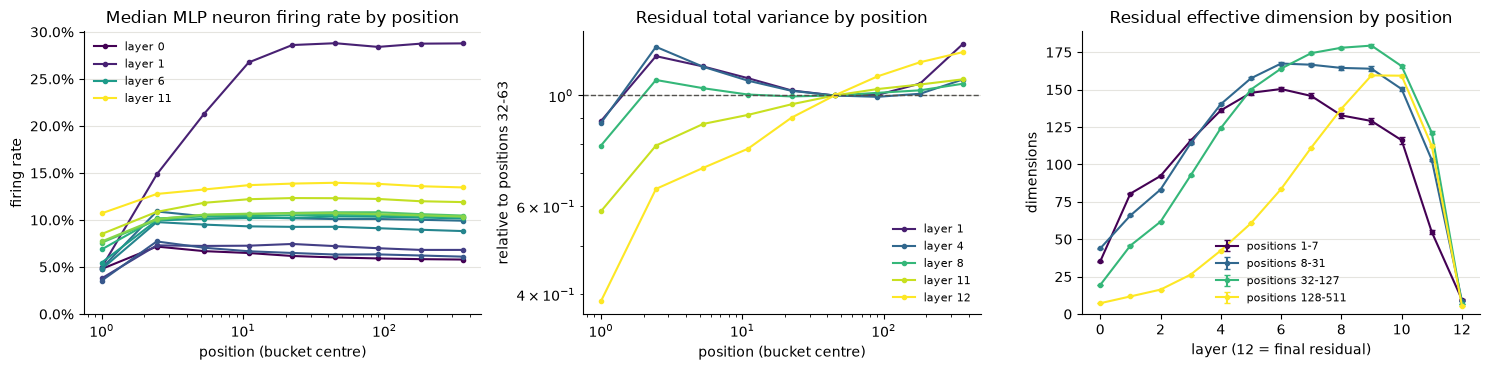

In [15]:
A512 = Path("../results/atlas-512")
pos = duckdb.sql(f"select * from '{A512 / 'positions.parquet'}'").df()
rpos = np.load(A512 / "resid_positions.npz")
m512 = json.loads((A512 / "manifest.json").read_text())
print(f"{m512['n_rows']:,} rows x {m512['seq_len']} tokens from {m512['n_docs']:,} documents ({m512['dataset']} files {m512['files']})")
buckets = pos.groupby("bucket")[["pos_lo", "pos_hi"]].first()
centers = np.sqrt(buckets.pos_lo * buckets.pos_hi).to_numpy()  # geometric centre of each bucket, for log axes
blabel = {b: (f"{r.pos_lo}" if r.pos_lo == r.pos_hi else f"{r.pos_lo}-{r.pos_hi}") for b, r in buckets.iterrows()}
print("position buckets:", ", ".join(blabel.values()))

post_pos = pos[pos.kind == "post"]
res_pos = pos[pos.kind == "resid"]
fr = post_pos.groupby(["layer", "bucket"]).frac_pos.median().unstack()  # [layer, bucket]
tv = res_pos.assign(var=res_pos["std"] ** 2).groupby(["layer", "bucket"])["var"].sum().unstack()  # trace of covariance

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
cmap = plt.get_cmap("viridis")
for l in fr.index:
    axes[0].plot(centers, fr.loc[l].to_numpy(), "o-", ms=3, lw=1.5, color=cmap(l / 11), label=f"layer {l}" if l in (0, 1, 6, 11) else None)
axes[0].set(xscale="log", title="Median MLP neuron firing rate by position", xlabel="position (bucket centre)", ylabel="firing rate", ylim=(0, None))
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[0].legend(frameon=False, fontsize=8)
for i, l in enumerate([1, 4, 8, 11, 12]):
    axes[1].plot(centers, (tv.loc[l] / tv.loc[l, 5]).to_numpy(), "o-", ms=3, lw=1.5, color=cmap(l / 12), label=f"layer {l}")
axes[1].axhline(1, color=INK2, lw=1, ls="--")
axes[1].set(xscale="log", yscale="log", title="Residual total variance by position", xlabel="position (bucket centre)",
            ylabel="relative to positions 32-63")
axes[1].legend(frameon=False, fontsize=8)
cov_edges = rpos["edges"]
for j in range(len(cov_edges) - 1):
    hi = min(cov_edges[j + 1] - 1, m512["seq_len"] - 1)
    axes[2].errorbar(rpos["layer"], rpos["pr"][:, j], yerr=rpos["pr_err"][:, j], fmt="o-", ms=3, lw=1.5, capsize=2,
                     color=cmap(j / (len(cov_edges) - 2)), label=f"positions {cov_edges[j]}-{hi}")
axes[2].set(title="Residual effective dimension by position", xlabel="layer (12 = final residual)", ylabel="dimensions", ylim=(0, None))
axes[2].legend(frameon=False, fontsize=8)
for ax in axes:
    tidy(ax)
plt.tight_layout()
save(fig, "results_position_layers")

print("\nmedian MLP firing rate by position bucket (layers 0, 1, 6, 11):")
print(fr.loc[[0, 1, 6, 11]].rename(columns=blabel).map(lambda v: f"{v:.1%}").to_string())
print("\nresidual effective dimension by coarse position bucket:")
print("layer  " + "".join(f"{f'{cov_edges[j]}-{min(cov_edges[j + 1] - 1, 511)}':>16s}" for j in range(len(cov_edges) - 1)))
for i, l in enumerate(rpos["layer"]):
    print(f"{l:5d}  " + "".join(f"{rpos['pr'][i, j]:9.1f} ± {rpos['pr_err'][i, j]:<4.1f}" for j in range(len(cov_edges) - 1)))

In [16]:
# Offset dimensions (docs/results.md §2) by position: mean ± std over tokens.
od = res_pos[res_pos.unit.isin([64, 373, 447, 481]) & res_pos.layer.isin([1, 6, 11, 12])]
tbl = od.assign(cell=[f"{m:7.1f} ± {s:<5.1f}" for m, s in zip(od["mean"], od["std"])]).pivot(index=["unit", "layer"], columns="bucket", values="cell")
print(tbl.rename(columns=blabel).to_string())

bucket                    1              2-3              4-7             8-15            16-31            32-63           64-127          128-255          256-511
unit layer                                                                                                                                                         
64   1        -14.7 ± 1.1      -18.6 ± 1.6      -21.0 ± 1.5      -23.1 ± 1.4      -24.7 ± 1.4      -24.9 ± 1.4      -23.3 ± 1.4      -22.1 ± 1.3      -22.2 ± 2.0  
     6        -22.7 ± 1.3      -25.0 ± 1.4      -26.3 ± 1.4      -27.3 ± 1.5      -28.0 ± 1.9      -28.1 ± 2.1      -26.7 ± 2.1      -25.6 ± 2.1      -24.4 ± 3.1  
     11       -26.2 ± 1.4      -27.9 ± 1.6      -28.7 ± 1.6      -28.9 ± 1.6      -29.0 ± 1.9      -28.8 ± 2.1      -27.3 ± 2.1      -25.9 ± 2.0      -25.0 ± 3.0  
     12      -116.2 ± 23.1    -117.6 ± 31.6    -119.6 ± 33.4    -117.7 ± 33.0    -116.0 ± 34.2    -116.8 ± 35.4    -118.1 ± 36.5    -121.7 ± 37.9    -123.3 ± 38.9 
373  1        -2

**Per-unit position dependence.** For every unit, the shift of its mean between position buckets, in units of its
spread over all positions, against a noise floor from the bootstrap errors of the two buckets. Early positions
(1–7) and late positions (256–511) are each compared with mid-context (32–127, pooled from 32–63 and 64–127).

median |Δ mean| / std        MLP neurons (floor)        residual dims (floor)
  positions 1-7 vs 32-127          0.077 (0.0110)        0.172 (0.0123)
  positions 256-511 vs 32-127      0.018 (0.0052)        0.058 (0.0059)
  long-document selection          0.009 (0.0054)        0.011 (0.0061)


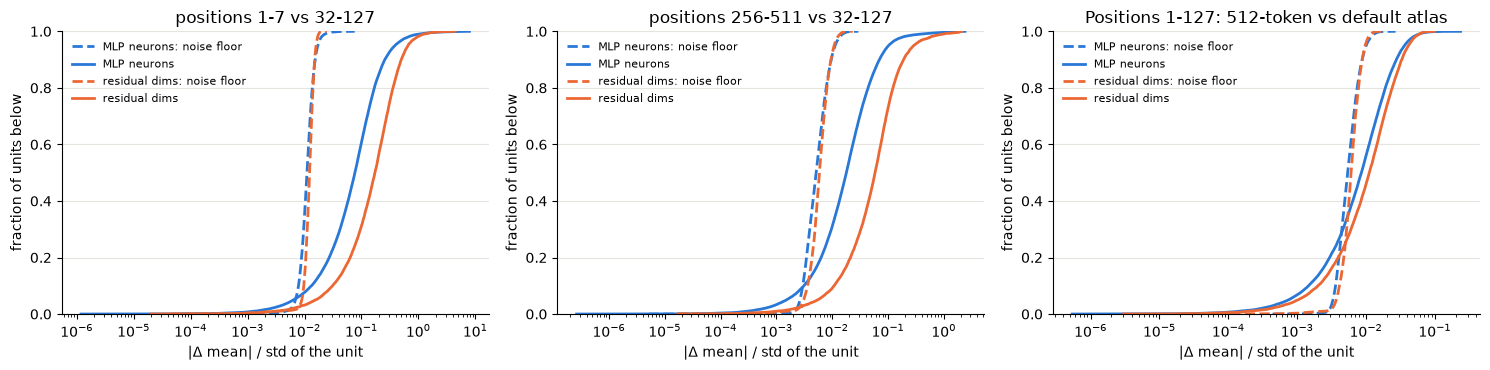

In [17]:
n512 = duckdb.sql(f"select * from '{A512 / 'neurons.parquet'}'").df().set_index(["hook", "unit"])

def pooled(df, bucket_ids):
    """Pool position buckets per unit: Chan-merged mean and std, and the error on the mean taken as fully correlated
    across buckets (an upper bound: the same documents feed every bucket)."""
    g = df[df.bucket.isin(bucket_ids)].copy()
    g["sx"], g["ss"] = g.n * g["mean"], g.n * (g["std"] ** 2 + g["mean"] ** 2)
    g["se"] = g.n * g["mean_err"]
    s = g.groupby(["hook", "unit"])[["n", "sx", "ss", "se"]].sum()
    mean = s.sx / s.n
    return pd.DataFrame({"n": s.n, "mean": mean, "std": np.sqrt(s.ss / s.n - mean**2), "mean_err": s.se / s.n})

mid = pooled(pos, [5, 6])
comparisons = {"positions 1-7 vs 32-127": pooled(pos, [0, 1, 2]), "positions 256-511 vs 32-127": pooled(pos, [8])}
spread = n512["std"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
print("median |Δ mean| / std        MLP neurons (floor)        residual dims (floor)")
for ax, (label, other) in zip(axes, comparisons.items()):
    d = (other["mean"] - mid["mean"]).abs() / spread.loc[other.index]
    fl = np.sqrt(other["mean_err"] ** 2 + mid["mean_err"] ** 2) / spread.loc[other.index]
    kinds = n512.loc[other.index, "kind"].to_numpy()
    row = []
    for i, (kind, name) in enumerate([("post", "MLP neurons"), ("resid", "residual dims")]):
        k = kinds == kind
        for vals, ls, lab in [(fl[k], "--", f"{name}: noise floor"), (d[k], "-", name)]:
            v = np.sort(vals.dropna().to_numpy())
            ax.plot(v, np.arange(1, len(v) + 1) / len(v), color=C[i], ls=ls, lw=2, label=lab)
        row.append(f"{np.median(d[k]):10.3f} ({np.median(fl[k]):.4f})")
    print(f"  {label:28s}" + "   ".join(row))
    ax.set(xscale="log", ylim=(0, 1), title=label, xlabel="|Δ mean| / std of the unit", ylabel="fraction of units below")
    ax.legend(frameon=False, fontsize=8)

# Document selection: positions 1-127 here (documents of at least 511 tokens) vs the default atlas (at least 127).
sel = pooled(pos, list(range(7)))
a128 = neurons.set_index(["hook", "unit"])
d = (sel["mean"] - a128.loc[sel.index, "mean"]).abs() / a128.loc[sel.index, "std"]
fl = np.sqrt(sel["mean_err"] ** 2 + a128.loc[sel.index, "mean_err"] ** 2) / a128.loc[sel.index, "std"]
kinds = a128.loc[sel.index, "kind"].to_numpy()
row = []
for i, (kind, name) in enumerate([("post", "MLP neurons"), ("resid", "residual dims")]):
    k = kinds == kind
    for vals, ls, lab in [(fl[k], "--", f"{name}: noise floor"), (d[k], "-", name)]:
        v = np.sort(vals.dropna().to_numpy())
        axes[2].plot(v, np.arange(1, len(v) + 1) / len(v), color=C[i], ls=ls, lw=2, label=lab)
    row.append(f"{np.median(d[k]):10.3f} ({np.median(fl[k]):.4f})")
print(f"  {'long-document selection':28s}" + "   ".join(row))
axes[2].set(xscale="log", ylim=(0, 1), title="Positions 1-127: 512-token vs default atlas", xlabel="|Δ mean| / std of the unit",
            ylabel="fraction of units below")
axes[2].legend(frameon=False, fontsize=8)
for ax in axes:
    tidy(ax)
plt.tight_layout()
save(fig, "results_position_units")

**Reading it.**

- **Layer 1's high firing rate is a property of position.** Its median neuron fires on 5% of tokens at position 1,
  15% at 2–3, 21% at 4–7 and 27% at 8–15, then holds at about 29% from position 16 on. Every layer fires less at
  position 1, and firing rates are flat from about position 16 out to 511.
- **The offset dimensions are largest at the start of the context.** In layer 11, dimension 447 falls from 125 at
  position 1 to 80 at positions 256–511, and 481 from 132 to 82; in layer 1, 373 goes from −27 to −13. Dimension 64
  does the opposite, growing from −15 at position 1 to about −25 by position 16.
- **Late positions differ a little, early ones more.** Against mid-context (32–127), positions 256–511 shift a typical
  unit by 0.018 of its spread (MLP neurons) and 0.058 (residual dimensions), 3.5–10× the noise floor; positions 1–7
  shift it by 0.077 and 0.17.
- **Long documents look like the rest.** Positions 1–127 of documents with at least 511 tokens differ from the default
  atlas by about 0.01 of a unit's spread, under 2× the floor and a third of the FineWeb shift (§5).
- **Caution on the per-bucket covariance.** A bucket's covariance mixes the variation between positions inside it with
  the variation between tokens at the same position. At layer 0, the position embedding alone is 51% of the variance
  in positions 128–511 (and 9–24% in the narrower buckets), lying almost entirely in about 2 directions. That is why
  the effective dimension of the widest bucket collapses to 7 there. The effective-dimension and total-variance panels
  therefore measure position spread as well as token content; separating them needs a covariance within each position.

## 8. Dependence on centering the residual stream

Everything above follows TransformerLens's processed convention, as the pretrained SAEs do. For the residual stream
that means each token's mean over d_model is removed: centering the weights that write to the stream is linear, so it
equals subtracting that mean. Unprocessed weights (plain Hugging Face, or TransformerLens without processing) leave it
in. The `hf-raw` backend does exactly that, on the same tokens as the default atlas:

    python -m atlas run results/atlas-raw --shards 16 --backend hf-raw   # tokens.npy copied from results/atlas

MLP activations should be identical: LayerNorm removes the mean before every MLP. In the residual stream the raw
activation is the centered one plus m·**1**, where m is the token's mean over the 768 dimensions. The all-ones direction
is orthogonal to everything in the centered stream, so the raw total variance is the centered one plus the variance
along **1**, exactly, and any change in effective dimension comes from that single direction.

MLP neurons, raw vs centered: max |Δ mean| / std 0.0e+00, max |Δ firing rate| 0.0e+00

layer  total var: centered      raw   raw - centered   along 1 (share of raw)   E[m]   std(m)   eff. dim: centered   raw
    0                11.6      11.7           0.0         0.0 ( 0.0%)  -0.002   0.003         14.3 ± 0.0    14.3 ± 0.0
    1              1033.2    1033.5           0.3         0.3 ( 0.0%)  -0.013   0.021         31.2 ± 0.0    31.1 ± 0.0
    2              1322.1    1322.5           0.4         0.4 ( 0.0%)  -0.019   0.024         46.2 ± 0.0    46.2 ± 0.0
    3              1662.8    1663.2           0.4         0.4 ( 0.0%)  -0.018   0.023         71.8 ± 0.1    71.8 ± 0.1
    4              2156.7    2157.1           0.4         0.4 ( 0.0%)  -0.018   0.024        104.0 ± 0.1   103.9 ± 0.1
    5              2667.8    2668.4           0.5         0.5 ( 0.0%)  -0.014   0.026        131.6 ± 0.2   131.6 ± 0.2
    6              3379.4    3380.0           0.6         0.6 ( 0.0%)  -0.007 


offset (layer, dimension) pairs with |mean| > 3 std: centered 79, raw 79, in both 78
  dim 64: mean centered / raw at layers 1, 6, 11, 12: -23.7 / -23.7, -27.2 / -27.2, -28.1 / -27.9, -118.9 / -119.0
  dim 373: mean centered / raw at layers 1, 6, 11, 12: -16.2 / -16.2, -21.3 / -21.3, -93.8 / -93.6, -143.0 / -143.1
  dim 447: mean centered / raw at layers 1, 6, 11, 12: 17.3 / 17.3, 32.0 / 32.0, 89.4 / 89.6, 127.5 / 127.4
  dim 481: mean centered / raw at layers 1, 6, 11, 12: 0.4 / 0.3, 6.4 / 6.4, 92.8 / 93.0, 133.3 / 133.2


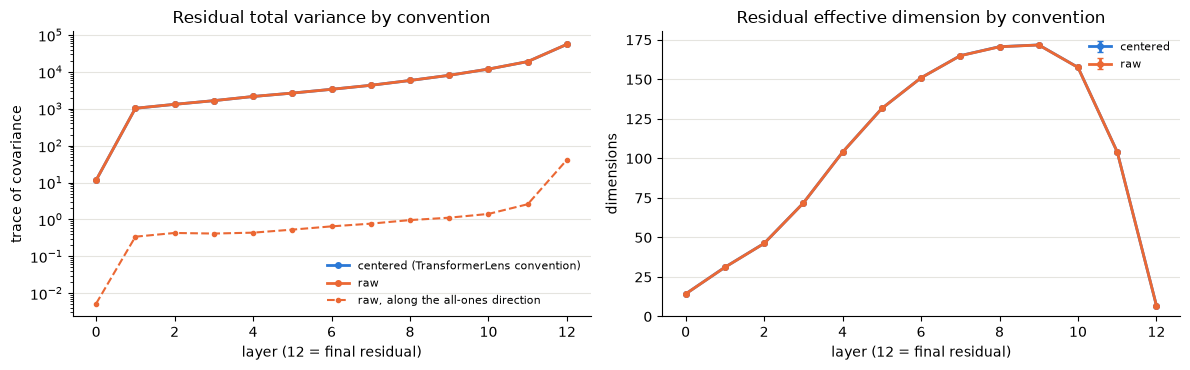

In [18]:
RAW = Path("../results/atlas-raw")
raw_n = duckdb.sql(f"select * from '{RAW / 'neurons.parquet'}'").df()
raw_r = np.load(RAW / "resid.npz")
assert (raw_n.hook.to_numpy() == neurons.hook.to_numpy()).all() and (raw_n.unit.to_numpy() == neurons.unit.to_numpy()).all()
mm = (neurons.kind == "post").to_numpy()
print(f"MLP neurons, raw vs centered: max |Δ mean| / std {np.max(np.abs(raw_n['mean'] - neurons['mean'])[mm] / neurons['std'][mm]):.1e}, "
      f"max |Δ firing rate| {np.max(np.abs(raw_n.frac_pos - neurons.frac_pos)[mm]):.1e}")

d = raw_r["cov"].shape[-1]
u = np.ones(d) / np.sqrt(d)
var_ones = np.einsum("i,lij,j->l", u, raw_r["cov"], u)  # raw variance along the all-ones direction = d * Var(m)
m_mean = raw_r["mean"].mean(1)  # E[m] per layer: the mean over dimensions of the per-dimension means
tc, tr_ = resid["total_var"], raw_r["total_var"]
print("\nlayer  total var: centered      raw   raw - centered   along 1 (share of raw)   E[m]   std(m)   eff. dim: centered   raw")
for l in layers:
    print(f"{l:5d}  {tc[l]:18.1f} {tr_[l]:9.1f} {tr_[l] - tc[l]:13.1f} {var_ones[l]:11.1f} ({var_ones[l] / tr_[l]:5.1%})"
          f" {m_mean[l]:7.3f} {np.sqrt(var_ones[l] / d):7.3f}   {resid['pr'][l]:10.1f} ± {resid['pr_err'][l]:.1f}  {raw_r['pr'][l]:6.1f} ± {raw_r['pr_err'][l]:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(layers, tc, "o-", color=C[0], lw=2, ms=4, label="centered (TransformerLens convention)")
axes[0].plot(layers, tr_, "o-", color=C[1], lw=2, ms=4, label="raw")
axes[0].plot(layers, var_ones, "o--", color=C[1], lw=1.5, ms=3, label="raw, along the all-ones direction")
axes[0].set(yscale="log", title="Residual total variance by convention", xlabel="layer (12 = final residual)", ylabel="trace of covariance")
axes[1].errorbar(layers, resid["pr"], yerr=resid["pr_err"], fmt="o-", color=C[0], lw=2, ms=4, capsize=2, label="centered")
axes[1].errorbar(layers, raw_r["pr"], yerr=raw_r["pr_err"], fmt="o-", color=C[1], lw=2, ms=4, capsize=2, label="raw")
axes[1].set(title="Residual effective dimension by convention", xlabel="layer (12 = final residual)", ylabel="dimensions", ylim=(0, None))
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
    tidy(ax)
plt.tight_layout()
save(fig, "results_convention")

rr, rc = raw_n[~mm], neurons[~mm]
off_raw, off_c = (rr["mean"].abs() > 3 * rr["std"]), (rc["mean"].abs() > 3 * rc["std"])
print(f"\noffset (layer, dimension) pairs with |mean| > 3 std: centered {off_c.sum()}, raw {off_raw.sum()}, in both {(off_raw & off_c).sum()}")
for dim in (64, 373, 447, 481):
    row = rc[rc.unit == dim].set_index("layer"); rowr = rr[rr.unit == dim].set_index("layer")
    print(f"  dim {dim}: mean centered / raw at layers 1, 6, 11, 12: " +
          ", ".join(f"{row.loc[l, 'mean']:.1f} / {rowr.loc[l, 'mean']:.1f}" for l in (1, 6, 11, 12)))

**Reading it.** For GPT-2 small, centering the residual stream changes almost nothing the atlas measures. MLP
neurons are identical to the last bit. In the residual stream, a token's mean over d_model is tiny: on average −0.09
to 0.17, with a spread of 0.003–0.23 across tokens, against unit spreads that grow from about 0.1 to over 8 with depth.
The all-ones direction therefore carries at most 0.1% of the raw variance (at the final residual) and 0.0% elsewhere,
and raw minus centered total variance equals the variance along it at every layer, as it must. Effective dimensions
agree within errors, and the offset dimensions are the same (79 pairs either way, 78 in common; the other differs only
at the 3-std threshold), with means moved by at most 0.2. LayerNorm removes the mean before every block reads the
stream, so the model gets almost no training signal along the all-ones direction, which is consistent with it staying
nearly empty. The systematic is negligible here; it would matter for a model or tool where that direction is not
nearly empty.

## 9. The gate into stage 2

Before using a pretrained SAE's features, check that it reproduces its release's metrics on this pipeline: same hook,
same processing convention, same BOS and context handling. `python/sae_gate.py` runs Joseph Bloom's
`gpt2-small-res-jb` residual SAEs (24,576 features at each `hook_resid_pre`) on the default atlas's tokens, through our
HF backend, with SAELens's definitions of the metrics:

    run-sae-gate   # = python -m sae_gate results/atlas --out results/sae-gate; 250 rows from each of 8 files per layer

- **L0**: nonzero features per token, without BOS.
- **Variance explained**, centered: 1 − E‖x − x̂‖² / (E‖x‖² − ‖E x‖²), SAELens's current definition; and about the
  origin, 1 − E‖x − x̂‖² / E‖x‖², as the release post computed it.
- **CE loss score**: (CE_zero − CE_sae) / (CE_zero − CE_clean), with the reconstruction spliced in everywhere but BOS.
- **Alive fraction**: features that fire at least once on these tokens.

The references are the per-layer table in the release post (SAELens's own reference values for this release are
rough). On 32 rows per layer the gate also recomputes the residual stream and the per-token losses with
TransformerLens's HookedTransformer, loaded as SAELens recommends, as an independent check of our conventions.

gpt2-small-res-jb: 24,576 features; 254,000 tokens per layer; SAE trained on Skylion007/openwebtext, context 128, BOS True, processing {"center_writing_weights": true}

layer    L0 (post)     var. explained: centered, about origin (post)   alive (post)   ΔCE (post)   CE score   TL check: resid, CE
    0   12.4 (12.24)    97.8%    98.9% (99.15%)    79.3% (80.0%)   0.020 (0.02)   0.999   6e-08, 9e-05
    1   14.7 (14.68)    95.0%    98.1% (98.37%)    83.1% (83.4%)   0.018 (0.03)   0.996   2e-06, 9e-05
    2   18.7 (18.80)    94.3%    97.8% (98.07%)    79.6% (80.0%)   0.064 (0.07)   0.987   2e-06, 9e-05
    3   26.0 (25.75)    92.0%    96.6% (96.97%)    86.3% (86.3%)   0.155 (0.18)   0.985   1e-06, 9e-05
    4   33.3 (33.14)    90.1%    95.3% (95.77%)    97.7% (97.7%)   0.122 (0.14)   0.992   2e-06, 9e-05
    5   44.1 (43.61)    88.8%    94.3% (94.90%)    99.7% (99.7%)   0.138 (0.15)   0.989   2e-06, 9e-05
    6   50.6 (49.68)    87.5%    93.3% (93.90%)    99.9% (100.0%)   0.138 (0.14)   

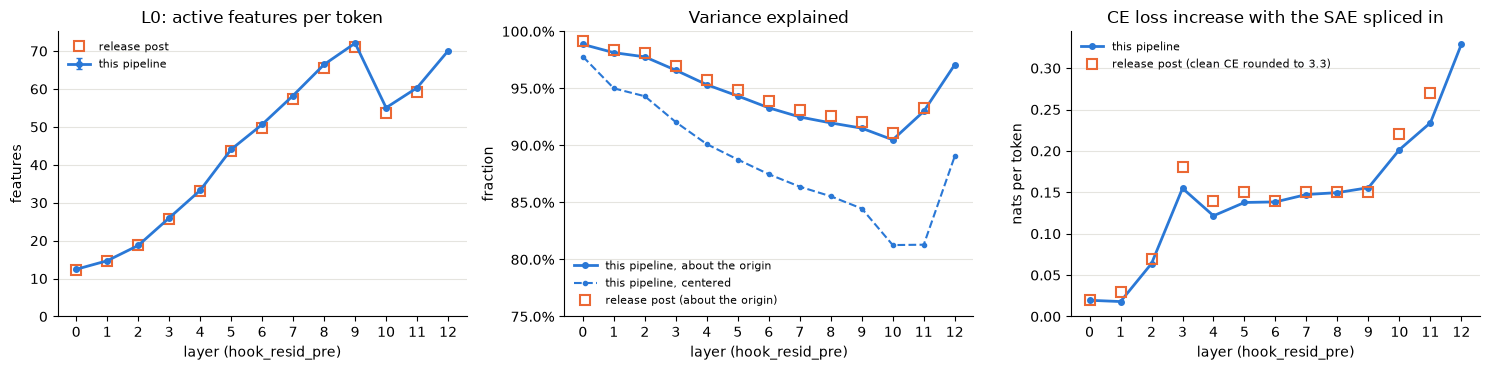

In [19]:
gate = pd.read_parquet("../results/sae-gate/gate.parquet")
print(f"{gate.release.iloc[0]}: {gate.d_sae.iloc[0]:,} features; {gate.n_tokens.iloc[0]:,} tokens per layer; "
      f"SAE trained on {gate.sae_dataset.iloc[0]}, context {gate.sae_context_size.iloc[0]}, BOS {gate.sae_prepend_bos.iloc[0]}, "
      f"processing {gate.sae_processing.iloc[0]}")
print("\nlayer    L0 (post)     var. explained: centered, about origin (post)   alive (post)   ΔCE (post)   CE score   TL check: resid, CE")
for r in gate.itertuples():
    print(f"{r.layer:5d}  {r.l0:5.1f} ({r.post_l0:5.2f})   {r.var_explained:6.1%}   {r.var_explained_origin:6.1%} ({r.post_var_explained_origin:6.2%})"
          f"   {1 - r.dead_frac:6.1%} ({r.post_alive_frac:5.1%})   {r.ce_sae - r.ce_clean:.3f} ({r.post_ce_sae - r.post_ce_clean:.2f})"
          f"   {r.ce_score:.3f}   {r.tl_resid_max_rel_diff:.0e}, {r.tl_ce_max_abs_diff:.0e}")
print(f"\nL0 vs post: worst {np.max(np.abs(gate.l0 / gate.post_l0 - 1)):.1%}; "
      f"variance explained about the origin vs post: worst {np.max(np.abs(gate.var_explained_origin - gate.post_var_explained_origin)) * 100:.1f} points; "
      f"alive vs post: worst {np.max(np.abs(1 - gate.dead_frac - gate.post_alive_frac)) * 100:.1f} points; "
      f"clean CE {gate.ce_clean.iloc[0]:.3f} (post: about 3.3)")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
ref = dict(color=C[1], ms=7, mfc="none", mew=1.5, ls="none")
axes[0].errorbar(gate.layer, gate.l0, yerr=gate.l0_err, fmt="o-", color=C[0], lw=2, ms=4, capsize=2, label="this pipeline")
axes[0].plot(gate.layer, gate.post_l0, "s", label="release post", **ref)
axes[0].set(title="L0: active features per token", xlabel="layer (hook_resid_pre)", ylabel="features", ylim=(0, None))
axes[1].plot(gate.layer, gate.var_explained_origin, "o-", color=C[0], lw=2, ms=4, label="this pipeline, about the origin")
axes[1].plot(gate.layer, gate.var_explained, "o--", color=C[0], lw=1.5, ms=3, label="this pipeline, centered")
axes[1].plot(gate.layer, gate.post_var_explained_origin, "s", label="release post (about the origin)", **ref)
axes[1].set(title="Variance explained", xlabel="layer (hook_resid_pre)", ylabel="fraction", ylim=(0.75, 1.0))
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[2].plot(gate.layer, gate.ce_sae - gate.ce_clean, "o-", color=C[0], lw=2, ms=4, label="this pipeline")
axes[2].plot(gate.layer, gate.post_ce_sae - gate.post_ce_clean, "s", label="release post (clean CE rounded to 3.3)", **ref)
axes[2].set(title="CE loss increase with the SAE spliced in", xlabel="layer (hook_resid_pre)", ylabel="nats per token", ylim=(0, None))
for ax in axes:
    ax.set_xticks(gate.layer)
    ax.legend(frameon=False, fontsize=8)
    tidy(ax)
plt.tight_layout()
save(fig, "results_sae_gate")

**Reading it.** The gate passes. Our pipeline reproduces TransformerLens's residual stream to about 10⁻⁶ and its
per-token losses to 10⁻⁴ at every layer, so the SAEs see exactly the activations SAELens would give them. Against the
release post, L0 agrees within 2.4%, alive features within 0.7 points, variance explained about the origin within 0.7
points (always slightly below), and the CE increase within the rounding of the post's clean CE. Centered variance
explained, SAELens's current definition, is 1–12 points lower: the post's definition credits the SAE for the residual
stream's constant offsets (the offset dimensions of `docs/results.md` §2), which its decoder bias reconstructs almost
for free. Our clean CE (3.50) is higher than the post's 3.3 because our rows start mid-document, so early positions have
little context; the increase from splicing in the SAE, which is what the gate tests, agrees.

## 10. Stage 2: the atlas in the SAE basis

With the gate passed, the gate-validated SAEs encode the residual stream inside the hooks, and their 24,576 features at
layers 6 and 9 become ordinary atlas units (`kind = "sae"`): firing rate, moments, histogram and top-20 contexts, on
the same tokens as the default atlas. At layer 9 every nonzero activation is also kept as a sparse event
(`events-L9-*.parquet`: row, pos, feature, value), for per-token queries such as the IOI analysis to come.

    mkdir -p results/atlas-sae && cp results/atlas/{tokens.npy,docs.npy,manifest.json} results/atlas-sae/
    python -m atlas run results/atlas-sae --shards 16 --batch-size 32 --hooks 'blocks.6.hook_resid_pre,blocks.9.hook_resid_pre' \
        --sae gpt2-small-res-jb --sae-layers 6,9 --sae-events 9
    python -m atlas export results/atlas-sae

Single features are checked against Neuronpedia, which hosts dashboards for these SAEs built from OpenWebText with
128-token prompts: 50 live features per layer, evenly spaced through our firing-rate distribution, fetched once from its
public API and cached under `results/neuronpedia/`.

layer   features   never fire   firing rate: 10% / median / 90%    fire on > 1%   L0 (sum of rates)   MLP neurons: median rate
    6     24,576          13     0.00018 / 0.00055 / 0.00547          1,043           50.7        0.102
    9     24,576           3     0.00035 / 0.00140 / 0.00746          1,494           72.1        0.105



Neuronpedia check (50 features per layer):
  layer 6: firing rate ours / Neuronpedia median 1.02 (16-84%: 0.92-1.10); max ours / Neuronpedia median 0.97; Neuronpedia's top-10 tokens among our top-20: median 100%, features sharing any 94%
  layer 9: firing rate ours / Neuronpedia median 1.00 (16-84%: 0.93-1.05); max ours / Neuronpedia median 0.97; Neuronpedia's top-10 tokens among our top-20: median 100%, features sharing any 88%

largest rate disagreements:
 layer  unit     rate      np_rate       max    np_max  token_overlap
     6  6819 0.000005 1.302083e-03  0.716004 60.039227            0.0
     9 21059 0.000001 3.178914e-07  0.097223  0.178176            0.0
     6 11350 0.000263 1.560847e-04 45.074566 46.935448            1.0
     6 17583 0.000230 2.915064e-04 60.057652 62.336056            1.0


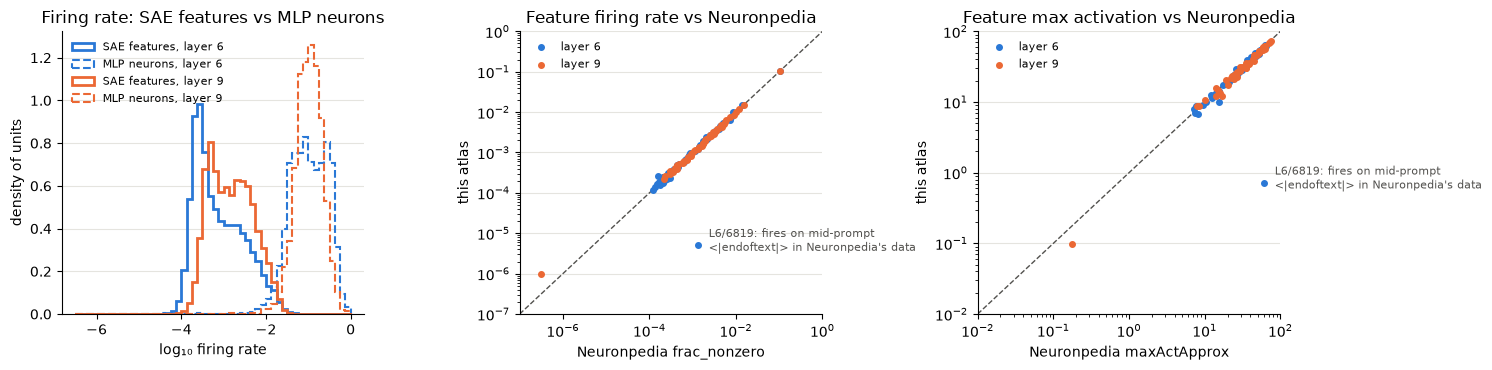

In [20]:
from sae_gate import neuronpedia_features

ASAE = Path("../results/atlas-sae")
feat = duckdb.sql(f"select * from '{ASAE / 'neurons.parquet'}' where kind = 'sae'").df()
ftop = duckdb.sql(f"select * from '{ASAE / 'topk.parquet'}' where kind = 'sae'").df()
print("layer   features   never fire   firing rate: 10% / median / 90%    fire on > 1%   L0 (sum of rates)   MLP neurons: median rate")
for l, g in feat.groupby("layer"):
    fr = g.frac_pos
    print(f"{l:5d} {len(g):10,d} {int((fr == 0).sum()):11d}     {np.quantile(fr[fr > 0], .1):.5f} / {fr.median():.5f} / {np.quantile(fr, .9):.5f}"
          f"   {int((fr > .01).sum()):12,d}   {fr.sum():12.1f}        {mlp[mlp.layer == l].frac_pos.median():.3f}")

def np_sample(l, n=50):
    g = feat[(feat.layer == l) & (feat.frac_pos > 0)].sort_values("frac_pos")
    pick = g.unit.to_numpy()[np.linspace(0, len(g) - 1, n).round().astype(int)]
    recs = neuronpedia_features(f"{l}-res-jb", pick, Path("../results/neuronpedia"))
    rows = []
    for i in pick:
        r, ours = recs[i], g.set_index("unit").loc[i]
        np_tokens = [a["tokens"][a["maxValueTokenIndex"]].strip() for a in r["activations"] if a.get("maxValue", 0) > 0][:10]
        our_tokens = {t.strip() for t in ftop[(ftop.layer == l) & (ftop.unit == i) & (ftop.side == "top")].token}
        rows.append({"layer": l, "unit": i, "rate": ours.frac_pos, "np_rate": r["frac_nonzero"], "max": ours["max"],
                     "np_max": r["maxActApprox"], "token_overlap": np.mean([t in our_tokens for t in np_tokens]) if np_tokens else np.nan,
                     "explanation": (r.get("explanations") or [{}])[0].get("description")})
    return pd.DataFrame(rows)

chk = pd.concat([np_sample(6), np_sample(9)], ignore_index=True)
print("\nNeuronpedia check (50 features per layer):")
for l, g in chk.groupby("layer"):
    ok = g.np_rate > 0
    lr = np.log10(g.rate[ok] / g.np_rate[ok])
    print(f"  layer {l}: firing rate ours / Neuronpedia median {10 ** lr.median():.2f} (16-84%: {10 ** lr.quantile(.16):.2f}-{10 ** lr.quantile(.84):.2f}); "
          f"max ours / Neuronpedia median {(g['max'] / g.np_max).median():.2f}; Neuronpedia's top-10 tokens among our top-20: median "
          f"{g.token_overlap.median():.0%}, features sharing any {(g.token_overlap > 0).mean():.0%}")
worst = chk.assign(r=np.abs(np.log10(chk.rate / chk.np_rate))).nlargest(4, "r")
print("\nlargest rate disagreements:")
print(worst[["layer", "unit", "rate", "np_rate", "max", "np_max", "token_overlap"]].to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
bins = np.linspace(-6.5, 0, 53)
for i, l in enumerate((6, 9)):
    fr = feat[feat.layer == l].frac_pos
    axes[0].hist(np.log10(fr[fr > 0]), bins=bins, histtype="step", lw=2, color=C[i], label=f"SAE features, layer {l}", density=True)
    nr = mlp[mlp.layer == l].frac_pos
    axes[0].hist(np.log10(nr[nr > 0]), bins=bins, histtype="step", lw=1.5, ls="--", color=C[i], label=f"MLP neurons, layer {l}", density=True)
    g = chk[chk.layer == l]
    axes[1].scatter(g.np_rate, g.rate, s=16, color=C[i], label=f"layer {l}", zorder=3)
    axes[2].scatter(g.np_max, g["max"], s=16, color=C[i], label=f"layer {l}", zorder=3)
axes[0].set(title="Firing rate: SAE features vs MLP neurons", xlabel="log₁₀ firing rate", ylabel="density of units")
# Limits that include every sampled feature, so outliers are not clipped out of view.
lims = {"rate": (10 ** np.floor(np.log10(min(chk.rate.min(), chk.np_rate.min()))), 1),
        "max": (10 ** np.floor(np.log10(min(chk["max"].min(), chk.np_max.min()))), 100)}
for ax, lim, title, xl, yl in [(axes[1], lims["rate"], "Feature firing rate vs Neuronpedia", "Neuronpedia frac_nonzero", "this atlas"),
                               (axes[2], lims["max"], "Feature max activation vs Neuronpedia", "Neuronpedia maxActApprox", "this atlas")]:
    ax.plot(lim, lim, color=INK2, lw=1, ls="--")
    ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, title=title, xlabel=xl, ylabel=yl)
odd = chk[(chk.layer == 6) & (chk.unit == 6819)]
for ax, x, y in [(axes[1], "np_rate", "rate"), (axes[2], "np_max", "max")]:
    if len(odd):
        ax.annotate("L6/6819: fires on mid-prompt\n<|endoftext|> in Neuronpedia's data", (odd[x].iloc[0], odd[y].iloc[0]),
                    xytext=(8, -4), textcoords="offset points", fontsize=8, color=INK2)
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
    tidy(ax)
plt.tight_layout()
save(fig, "results_sae_features")

In [21]:
# The decoder bias vs the residual stream's mean (docs/results.md §2's offset dimensions).
from sae_gate import load_sae
for l in (6, 9):
    sae_l = load_sae("gpt2-small-res-jb", f"blocks.{l}.hook_resid_pre", "cpu")
    b, mu = sae_l.b_dec.detach().double().numpy(), resid["mean"][l]
    print(f"layer {l}: |mean| {np.linalg.norm(mu):.1f}, |b_dec| {np.linalg.norm(b):.1f}, cos(b_dec, mean) {b @ mu / np.linalg.norm(b) / np.linalg.norm(mu):.3f}, "
          f"|mean - b_dec| / |mean| {np.linalg.norm(mu - b) / np.linalg.norm(mu):.2f}; offset dims (mean / b_dec): "
          + ", ".join(f"{d}: {mu[d]:.1f} / {b[d]:.1f}" for d in (64, 373, 447, 481)))

/Users/ryan/Development/gpt2-atlas/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/ryan/Development/gpt2-atlas/.venv/lib/python3.13/site-packages/sae_lens/saes/sae.py:256: UserWarning: 
This SAE has non-empty model_from_pretrained_kwargs. 
For optimal performance, load the model like so:
model = HookedSAETransformer.from_pretrained_no_processing(..., **cfg.model_from_pretrained_kwargs)
  warnings.warn(


layer 6: |mean| 54.2, |b_dec| 53.8, cos(b_dec, mean) 0.993, |mean - b_dec| / |mean| 0.12; offset dims (mean / b_dec): 64: -27.2 / -26.2, 373: -21.3 / -20.4, 447: 32.0 / 32.2, 481: 6.4 / 6.6


layer 9: |mean| 82.2, |b_dec| 83.3, cos(b_dec, mean) 0.994, |mean - b_dec| / |mean| 0.11; offset dims (mean / b_dec): 64: -27.7 / -26.8, 373: -34.4 / -34.2, 447: 49.3 / 51.3, 481: 37.0 / 38.1


In [22]:
# Example features: the densest at layer 9, and three from the Neuronpedia sample (low, median, high rate).
def show_feature(l, i, n=5):
    r = feat[(feat.layer == l) & (feat.unit == i)].iloc[0]
    expl = chk[(chk.layer == l) & (chk.unit == i)].explanation
    print(f"L{l}/{i}: fires on {r.frac_pos:.3%} of tokens, max {r['max']:.1f}" + (f"; Neuronpedia: {expl.iloc[0]!r}" if len(expl) and expl.iloc[0] else ""))
    t = ftop[(ftop.layer == l) & (ftop.unit == i) & (ftop.side == "top")].sort_values("rank").head(n)
    for v, ctx in zip(t.value, t.context):
        print(f"    {v:6.2f}  {ctx[-80:]!r}")

show_feature(9, int(feat[feat.layer == 9].nlargest(1, "frac_pos").unit.iloc[0]))
s9 = chk[chk.layer == 9].reset_index(drop=True)
for j in (5, 25, 45):
    show_feature(9, int(s9.unit[j]))

L9/7155: fires on 10.651% of tokens, max 14.8; Neuronpedia: 'dates and months'
     14.76  '57%⏎⏎Common⏎⏎Dragon Hunter⏎⏎Absorb 20 dragon souls⏎⏎21.1%⏎⏎«Rare» 30.43%'
     13.02  'eference to that stupid billy goat. Anything« and» everything will seem possible'
     12.33  " have a large impact on a person's ability to exercise his« or» her legal rights"
     12.04  '%⏎⏎Common⏎⏎Dragon Hunter⏎⏎Absorb 20 dragon souls⏎⏎21.1%⏎⏎Rare« 30».43%⏎'
     11.90  'Dream.” Not only that, they’re being joined by Kristin Kontrol (a.k«.»a. Dee Dee'
L9/11770: fires on 0.035% of tokens, max 61.6; Neuronpedia: 'occurrences of the word "Fun"'
     61.62  'Async < T >( this IEnumerable < T > values ,« Fun»c < T ,'
     59.25  'cording to a lead researcherof Red Balloon Security, the« Fun»tenna radio signal'
     53.41  "to discuss what lies beneath Graham's exterior as well. («Fun» fact: Anderson is"
     50.57  ".com/… Character bio gallery: eurekatrollcat.deviantart.com/…« Fun» fact: Blue's"
     47.91  'o

**Reading it.**

- **Features are sparse, neurons are not.** The median feature fires on 0.06% (layer 6) or 0.14% (layer 9) of tokens,
  against about 10% for the median MLP neuron at the same layers, and almost none are dead over 1M tokens (13 and 3).
  About 1,000–1,500 features per layer fire on more than 1% of tokens.
- **Single features match Neuronpedia.** Firing rates agree with Neuronpedia's to a median ratio of 1.00–1.02 (the
  middle two-thirds within about ±10%), maxima to 0.97 (slightly lower here: 1M tokens against its 3.1M), and its top-10
  activating tokens are among our top-20 for a median of 100% of them.
- **One outlier is a document-boundary feature.** L6/6819 fires on 5 of our 1M tokens but on 0.13% of Neuronpedia's,
  always on an `<|endoftext|>` in the middle of a prompt, where one document ends and the next begins. Neuronpedia's
  prompts concatenate documents; our rows hold one document window after a BOS, which is excluded, so such features
  have nothing to fire on here. (The other outlier, L9/21059, is about equally rare in both.)
- **The decoder bias is the residual stream's mean.** cos(b_dec, mean) is 0.993–0.994, and the offset dimensions agree
  within a few percent: the SAE stores the constant offsets in its bias, which is why §9's variance explained about the
  origin runs so far above the centered value.
- **The examples read as features.** L9/11770 fires on the token "Fun" ("Func", "Funtenna", "Fun fact"), L9/23599 on
  the unit in "over the last five years / three decades", matching Neuronpedia's explanations. The densest feature,
  L9/7155 (11% of tokens), fires on conjunctions and punctuation in our top contexts, which Neuronpedia's "dates and
  months" label does not obviously describe.

## 11. Stage 2: the IOI repair in the SAE basis

ioi-hydra found that mean-ablating the three name-mover heads {9.9, 9.6, 10.0} removes 4.57 logits of direct effect,
yet the logit difference LD = logit(IO) − logit(S) does not drop: the network repairs 103% of the damage, mostly by
the copy-suppression head 10.7 releasing its brake and backup heads in layers 10–11 stepping up. Head-level accounting
cannot say whether the repair rebuilds the same *representation* or reaches the same LD another way. SAE features can.

`python/ioi.py` ports ioi-hydra's 128 prompts and its mean ablation to our HF backend, and first reproduces its
head-level numbers. Then, at each prompt's final token, it encodes the residual stream with the gate-validated SAEs at
three points, clean against ablated:

- **before layer 10**, after 9.9 and 9.6 are ablated: the damage;
- **before layer 11**, after layer 10's brake (10.7) and backups have responded;
- **the final residual stream**, which the unembedding reads.

The final LayerNorm is linear given a run's scale, so LD splits exactly into the SAE's features, its decoder bias and
its error: LD = Σ_f a_f (W_dec[f] · d) / scale + (b_dec · d) / scale + (error · d) / scale + const, with
d = γ ⊙ (W_U[IO] − W_U[S]). At the two earlier points the same projection is a logit lens (each point's own scale), an
approximation. A **control** ablation, three heads in layers 9–10 with negligible direct effect and no role in the
circuit, shows how much features move under an ablation that should not matter.

In [23]:
import ioi
from atlas import load_tokenizer
from sae_gate import load_sae, resid_hook_name, neuronpedia_features

hf_model = HFGPT2("mps" if torch.backends.mps.is_available() else "cpu")
ds = ioi.make_ioi_dataset(load_tokenizer())
clean_run = ioi.run(hf_model, ds)
mean_ref = ioi.mean_reference(ioi.capture_z(hf_model, ds.corrupt_tokens.to(hf_model.model.device), range(12)), ds.template_id)
with ioi.ablate_heads(hf_model, ioi.NAME_MOVERS, mean_ref):
    abl_run = ioi.run(hf_model, ds)
direct = -sum(abl_run["de"][:, l, h] - clean_run["de"][:, l, h] for l, h in ioi.NAME_MOVERS)
total = clean_run["ld"] - abl_run["ld"]
recon = (clean_run["resid"][12] * clean_run["d"]).sum(-1) / clean_run["scale"] + clean_run["const"]
print(f"{len(ds)} prompts, e.g. {ds.prompts[0]!r}")
print("reproducing ioi-hydra (its values in brackets):")
for label, x, ref in [("clean LD", clean_run["ld"], 3.38), ("ablated LD", abl_run["ld"], 3.53), ("direct effect lost", direct, 4.57)]:
    m, lo, hi = ioi.bootstrap_mean(x)
    print(f"  {label:20s} {m:6.2f} [{lo:.2f}, {hi:.2f}]   ({ref})")
print(f"  repair fraction      {(direct - total).mean() / direct.mean():6.3f}   (1.03)")
print(f"  10.7 DE {clean_run['de'][:, 10, 7].mean():.2f} -> {abl_run['de'][:, 10, 7].mean():.2f} (-2.06 -> +0.07); "
      f"final LN scale {clean_run['scale'].mean():.1f} -> {abl_run['scale'].mean():.1f} (17.8 -> 16.6); "
      f"linear final-LN split vs logits: max |diff| {(recon - clean_run['ld']).abs().max():.0e}")

# Control: three heads in layers 9-10 with the smallest |direct effect|, outside ioi-hydra's circuit roles.
CIRCUIT = set(ioi.NAME_MOVERS) | {(10, 7), (11, 10), (10, 10), (10, 6), (10, 2), (10, 1), (11, 2), (9, 7), (9, 0), (11, 9)}
mag = clean_run["de"].abs().mean(0)
cands = sorted(((float(mag[l, h]), (l, h)) for l in (9, 10) for h in range(12) if (l, h) not in CIRCUIT))
CONTROL = [lh for _, lh in cands[:3]]
with ioi.ablate_heads(hf_model, CONTROL, mean_ref):
    ctl_run = ioi.run(hf_model, ds)
print(f"control heads {CONTROL}: mean |DE| {[round(c, 3) for c, _ in cands[:3]]}; LD {ctl_run['ld'].mean():.2f}")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 14902.70it/s]

128 prompts, e.g. 'When Susan and Robert went to the store, Robert gave a drink to'
reproducing ioi-hydra (its values in brackets):
  clean LD               3.38 [3.14, 3.61]   (3.38)
  ablated LD             3.53 [3.25, 3.82]   (3.53)
  direct effect lost     4.57 [4.29, 4.85]   (4.57)
  repair fraction       1.034   (1.03)
  10.7 DE -2.06 -> 0.07 (-2.06 -> +0.07); final LN scale 17.8 -> 16.6 (17.8 -> 16.6); linear final-LN split vs logits: max |diff| 2e-05


control heads [(9, 10), (9, 1), (10, 8)]: mean |DE| [0.014, 0.021, 0.023]; LD 3.37


In [24]:
eps = hf_model.model.ln_f.eps
POINTS = {10: "before layer 10", 11: "before layer 11", 12: "final residual"}
fa, saes_ioi = {}, {}
for L in POINTS:
    saes_ioi[L] = load_sae("gpt2-small-res-jb", resid_hook_name(L), "cpu")
    for name, r in (("clean", clean_run), ("ablated", abl_run), ("control", ctl_run)):
        x = r["resid"][L]
        sc = (x.pow(2).mean(-1) + eps).sqrt()  # this point's own scale: exact at the final residual, a logit lens before
        fa[L, name] = ioi.feature_attribution(saes_ioi[L], x, r["d"], sc) | {"lens": (x * r["d"]).sum(-1) / sc}

def compare(L, other):
    c, o = fa[L, "clean"], fa[L, other]
    on_c, on_o = c["acts"] > 0, o["acts"] > 0
    return {"L0": (on_c.sum(1).float(), on_o.sum(1).float()),
            "jaccard": (on_c & on_o).sum(1) / (on_c | on_o).sum(1),
            "mass_kept": torch.minimum(c["acts"], o["acts"]).sum(1) / c["acts"].sum(1),
            "cos_contrib": torch.nn.functional.cosine_similarity(c["contrib"], o["contrib"], dim=1),
            # Of the other run's feature LD, the share carried by features active in the clean run (ratio of totals).
            "share_from_clean_set": float((o["contrib"] * on_c).sum() / o["contrib"].sum())}

fmt = lambda x: "%.2f [%.2f, %.2f]" % ioi.bootstrap_mean(x)
print("point             run        L0     Jaccard with clean   clean activation mass kept   cos(LD contributions)   LD share from clean-active features")
for L, label in POINTS.items():
    for other in ("ablated", "control"):
        cm = compare(L, other)
        print(f"{label:16s}  {other:8s} {cm['L0'][0].mean():4.0f}->{cm['L0'][1].mean():<4.0f} {fmt(cm['jaccard']):>19s}   {fmt(cm['mass_kept']):>24s}   "
              f"{fmt(cm['cos_contrib']):>20s}   {cm['share_from_clean_set']:8.2f}")

print("\nLD split: features + decoder bias + SAE error (+ const at the final residual); before layer 12, a logit lens")
print("point             run        LD (lens)          features             error              bias")
for L, label in POINTS.items():
    for name in ("clean", "ablated"):
        f = fa[L, name]
        print(f"{label:16s}  {name:8s} {fmt(f['lens']):>16s}  {fmt(f['contrib'].sum(1)):>18s}  {fmt(f['error']):>18s}  {f['bias'].mean():6.2f}")
fc, fab = fa[12, "clean"], fa[12, "ablated"]
check = (fc["contrib"].sum(1) + fc["bias"] + fc["error"] + clean_run["const"] - clean_run["ld"]).abs().max()
print(f"\nexact at the final residual: features + bias + error + const - LD, max |diff| {check:.0e}")
d_feat, d_err = fab["contrib"].sum(1) - fc["contrib"].sum(1), fab["error"] - fc["error"]
d_rest = (fab["bias"] + abl_run["const"]) - (fc["bias"] + clean_run["const"])
print(f"change in LD under the ablation, {fmt(abl_run['ld'] - clean_run['ld'])}: features {fmt(d_feat)}, SAE error {fmt(d_err)}, bias and const {fmt(d_rest)}")

point             run        L0     Jaccard with clean   clean activation mass kept   cos(LD contributions)   LD share from clean-active features
before layer 10   ablated    91->55     0.47 [0.45, 0.48]          0.53 [0.51, 0.55]      0.39 [0.35, 0.43]       1.15
before layer 10   control    91->90     0.98 [0.97, 0.98]          0.99 [0.99, 0.99]      1.00 [1.00, 1.00]       1.00
before layer 11   ablated    68->62     0.55 [0.54, 0.57]          0.69 [0.68, 0.70]      0.87 [0.85, 0.89]       0.94
before layer 11   control    68->68     0.97 [0.97, 0.98]          0.99 [0.99, 0.99]      1.00 [1.00, 1.00]       1.00
final residual    ablated    73->61     0.57 [0.56, 0.58]          0.69 [0.67, 0.70]      0.92 [0.90, 0.94]       0.97
final residual    control    73->73     0.97 [0.97, 0.98]          0.99 [0.99, 0.99]      1.00 [1.00, 1.00]       1.00

LD split: features + decoder bias + SAE error (+ const at the final residual); before layer 12, a logit lens
point             run        L

In [25]:
# Is the SAE error just shrinkage? L1-trained SAEs under-activate, leaving part of the error parallel to the features'
# part of the reconstruction, f (W_dec a, scaled back for normalizing SAEs). Split the error e = alpha f + rest.
def error_split(sae_L, x, d, sc):
    a = sae_L.encode(x)
    s, m = getattr(sae_L, "ln_std", None), getattr(sae_L, "ln_mu", None)
    s = torch.ones(len(x), 1) if s is None else s.detach().clone()
    x_hat = sae_L.decode(a)
    f = s * (a @ sae_L.W_dec)
    e = x - x_hat
    alpha = (e * f).sum(-1) / (f * f).sum(-1)
    par, rest = alpha[:, None] * f, e - alpha[:, None] * f
    ld = lambda v: (v * d).sum(-1) / sc
    return {"error": ld(e), "parallel": ld(par), "rest": ld(rest), "features": ld(f), "alpha": alpha,
            "rest_frac": rest.norm(dim=-1) / e.norm(dim=-1)}

print("point            run       error LD   = parallel to features (alpha)   + rest     features + parallel   |rest| / |error|")
for L in (11, 12):
    for name, r in (("clean", clean_run), ("ablated", abl_run)):
        x, d = r["resid"][L], r["d"]
        es = error_split(saes_ioi[L], x, d, (x.pow(2).mean(-1) + eps).sqrt())
        print(f"{POINTS[L]:15s}  {name:8s} {es['error'].mean():8.2f}   {es['parallel'].mean():12.2f} ({es['alpha'].mean():.2f})   {es['rest'].mean():12.2f}"
              f"   {(es['features'] + es['parallel']).mean():14.2f}   {es['rest_frac'].mean():14.2f}")

point            run       error LD   = parallel to features (alpha)   + rest     features + parallel   |rest| / |error|
before layer 11  clean        3.81           1.62 (0.33)           2.20             6.82             0.93
before layer 11  ablated      4.19           1.15 (0.31)           3.03             5.11             0.94


final residual   clean        1.56           0.29 (0.19)           1.27             2.11             0.96
final residual   ablated      1.97           0.25 (0.20)           1.72             1.81             0.96


feature   mean LD contribution: clean -> ablated   active on (% of prompts): clean -> ablated   Neuronpedia
  15719   +0.133 -> +0.120                     9% ->   6%                    details of a conflict involving false accusations and legal actions
    258   +0.127 -> +0.099                     8% ->  13%                    mentions of specific individuals and organizations
   9680   +0.084 -> +0.082                     5% ->   3%                    phrases related to current events and news, particularly involving peo
  18598   +0.093 -> +0.072                     9% ->   9%                    mentions of specific individuals and actions happening to them in a na
   3566   +0.071 -> +0.070                    18% ->  16%                    information related to sports statistics, with a focus on goaltenders 
  16815   +0.073 -> +0.061                     9% ->   5%                    technical specifications and terms related to electronic devices
  18069   +0.063 -> +0.057       

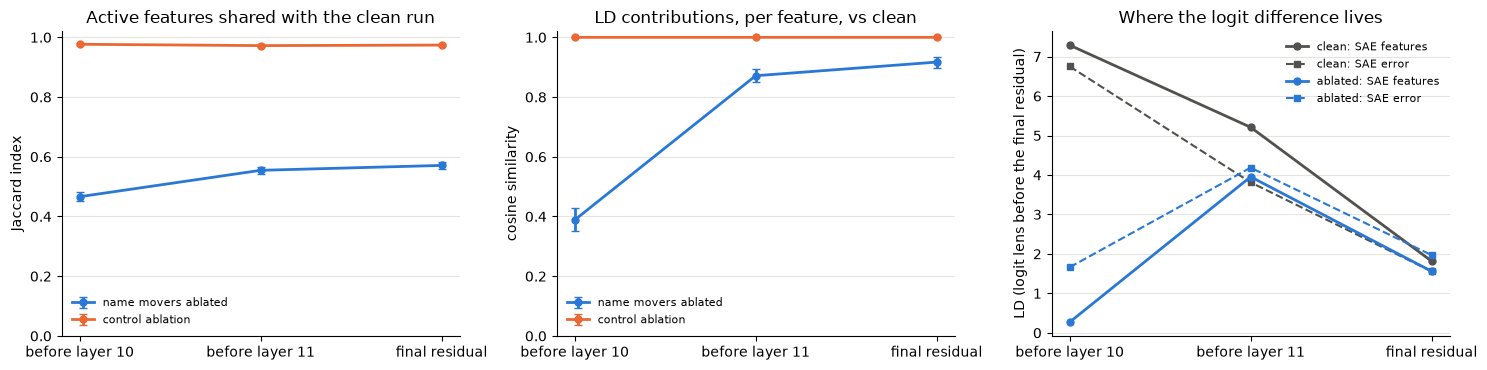

In [26]:
# The features carrying the most LD at the final residual, clean vs ablated, with Neuronpedia's explanations.
mc, ma = fc["contrib"].mean(0), fab["contrib"].mean(0)
top = torch.argsort(-(mc.abs() + ma.abs()))[:10].tolist()
recs = neuronpedia_features("12-res-jb", top, Path("../results/neuronpedia"))
print("feature   mean LD contribution: clean -> ablated   active on (% of prompts): clean -> ablated   Neuronpedia")
for f in top:
    expl = (recs[f].get("explanations") or [{}])[0].get("description", "")
    print(f"{f:7d}   {mc[f]:+.3f} -> {ma[f]:+.3f}{'':18s}{(fc['acts'][:, f] > 0).float().mean():5.0%} -> {(fab['acts'][:, f] > 0).float().mean():4.0%}{'':20s}{expl[:70]}")
gain = torch.argsort(-(ma - mc))[:5].tolist()
recs_g = neuronpedia_features("12-res-jb", gain, Path("../results/neuronpedia"))
print("\nlargest gains in LD contribution under the ablation:")
for f in gain:
    expl = (recs_g[f].get("explanations") or [{}])[0].get("description", "")
    print(f"{f:7d}   {mc[f]:+.3f} -> {ma[f]:+.3f}   active {(fc['acts'][:, f] > 0).float().mean():4.0%} -> {(fab['acts'][:, f] > 0).float().mean():4.0%}   {expl[:80]}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
pts = list(POINTS)
for i, other in enumerate(("ablated", "control")):
    js = [ioi.bootstrap_mean(compare(L, other)["jaccard"]) for L in pts]
    cs = [ioi.bootstrap_mean(compare(L, other)["cos_contrib"]) for L in pts]
    for ax, vals in ((axes[0], js), (axes[1], cs)):
        ax.errorbar(pts, [v[0] for v in vals], yerr=[[v[0] - v[1] for v in vals], [v[2] - v[0] for v in vals]],
                    fmt="o-", color=C[i], lw=2, ms=5, capsize=3, label=f"name movers ablated" if other == "ablated" else "control ablation")
axes[0].set(title="Active features shared with the clean run", ylabel="Jaccard index", ylim=(0, 1.02))
axes[1].set(title="LD contributions, per feature, vs clean", ylabel="cosine similarity", ylim=(0, 1.02))
for j, (name, col) in enumerate((("clean", INK2), ("ablated", C[0]))):  # blue = name movers ablated, as in the other panels
    feats = [fa[L, name]["contrib"].sum(1).mean() for L in pts]
    errs = [fa[L, name]["error"].mean() for L in pts]
    axes[2].plot(pts, feats, "o-", color=col, lw=2, ms=5, label=f"{name}: SAE features")
    axes[2].plot(pts, errs, "s--", color=col, lw=1.5, ms=4, label=f"{name}: SAE error")
axes[2].set(title="Where the logit difference lives", ylabel="LD (logit lens before the final residual)")
for ax in axes:
    ax.set_xticks(pts, [POINTS[L] for L in pts])
    ax.legend(frameon=False, fontsize=8)
    tidy(ax)
plt.tight_layout()
save(fig, "results_ioi_features")

**The dictionary systematic.** Is the off-dictionary half of the LD specific to this SAE? The same split, with
OpenAI's TopK SAEs (Gao et al. 2024; 32k and 128k features, k = 32) on the same three points (their
`blocks.{9,10,11}.hook_resid_post`), after their own gate (`docs/results.md` §11). They normalize each token to unit
std before encoding, which `feature_attribution` undoes, so the split stays exact.

/Users/ryan/Development/gpt2-atlas/.venv/lib/python3.13/site-packages/sae_lens/saes/sae.py:256: UserWarning: 
This SAE has non-empty model_from_pretrained_kwargs. 
For optimal performance, load the model like so:
model = HookedSAETransformer.from_pretrained_no_processing(..., **cfg.model_from_pretrained_kwargs)
  warnings.warn(


dictionary          point             L0   Jaccard   cos(LD contrib)   share from clean-active   LD in features: clean -> ablated   LD in error: clean -> ablated   off-dictionary (not shrinkage)
Bloom 24k (res-jb)  before layer 10    91     0.47             0.39                     1.15            7.29 ->  0.27               6.75 ->  1.66            6.10 ->  1.68
Bloom 24k (res-jb)  before layer 11    68     0.55             0.87                     0.94            5.21 ->  3.95               3.81 ->  4.19            2.20 ->  3.03
Bloom 24k (res-jb)  final residual     73     0.57             0.92                     0.97            1.82 ->  1.56               1.56 ->  1.97            1.27 ->  1.72
OpenAI 32k (v5)     before layer 10    32     0.46             0.46                     1.24            7.80 ->  0.70               6.18 ->  1.16            5.66 ->  1.17
OpenAI 32k (v5)     before layer 11    32     0.60             0.83                     0.84            5.01 ->  3.96    

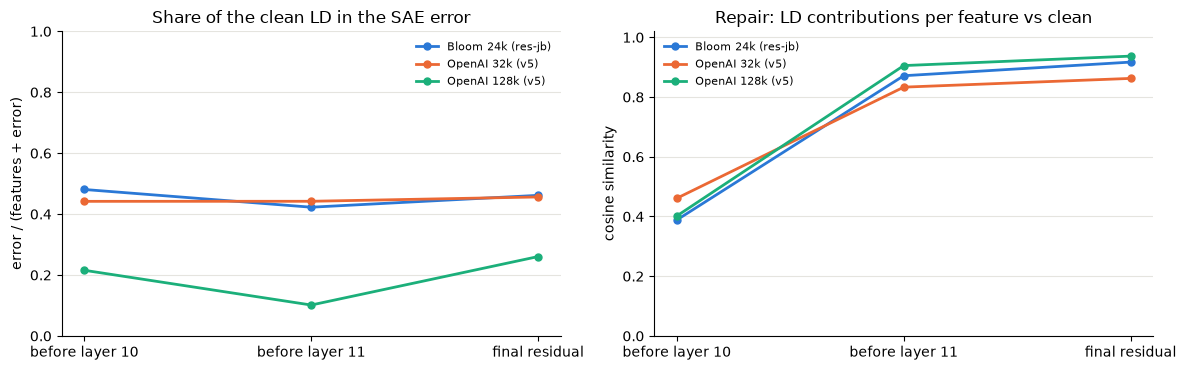

In [27]:
DICTS = {"Bloom 24k (res-jb)": "gpt2-small-res-jb", "OpenAI 32k (v5)": "gpt2-small-resid-post-v5-32k",
         "OpenAI 128k (v5)": "gpt2-small-resid-post-v5-128k"}
from sae_gate import sae_id_for
rows_d = []
for dname, rel in DICTS.items():
    for L in POINTS:
        sae_L = load_sae(rel, sae_id_for(rel, L), "cpu")
        res = {}
        for name, r in (("clean", clean_run), ("ablated", abl_run)):
            x = r["resid"][L]
            sc = (x.pow(2).mean(-1) + eps).sqrt()
            res[name] = ioi.feature_attribution(sae_L, x, r["d"], sc) | {"es": error_split(sae_L, x, r["d"], sc)}
        on_c, on_a = res["clean"]["acts"] > 0, res["ablated"]["acts"] > 0
        cc, ca = res["clean"]["contrib"], res["ablated"]["contrib"]
        rows_d.append({"dictionary": dname, "point": POINTS[L], "L": L,
                       "L0": float(on_c.sum(1).float().mean()),
                       "jaccard": float(((on_c & on_a).sum(1) / (on_c | on_a).sum(1)).mean()),
                       "cos_contrib": float(torch.nn.functional.cosine_similarity(cc, ca, dim=1).mean()),
                       "share_from_clean": float((ca * on_c).sum() / ca.sum()),
                       "feat_clean": float(cc.sum(1).mean()), "feat_abl": float(ca.sum(1).mean()),
                       "err_clean": float(res["clean"]["error"].mean()), "err_abl": float(res["ablated"]["error"].mean()),
                       "rest_clean": float(res["clean"]["es"]["rest"].mean()), "rest_abl": float(res["ablated"]["es"]["rest"].mean()),
                       "d_feat": ioi.bootstrap_mean(ca.sum(1) - cc.sum(1)), "d_err": ioi.bootstrap_mean(res["ablated"]["error"] - res["clean"]["error"])})
        del sae_L
dd = pd.DataFrame(rows_d)
print("dictionary          point             L0   Jaccard   cos(LD contrib)   share from clean-active   LD in features: clean -> ablated   LD in error: clean -> ablated   off-dictionary (not shrinkage)")
for r in dd.itertuples():
    print(f"{r.dictionary:19s} {r.point:16s} {r.L0:4.0f}   {r.jaccard:6.2f}   {r.cos_contrib:14.2f}   {r.share_from_clean:22.2f}   "
          f"{r.feat_clean:13.2f} -> {r.feat_abl:5.2f}   {r.err_clean:16.2f} -> {r.err_abl:5.2f}   {r.rest_clean:13.2f} -> {r.rest_abl:5.2f}")
fin = dd[dd.L == 12]
print("\nat the final residual, change under the ablation (95% intervals over prompts):")
for r in fin.itertuples():
    print(f"  {r.dictionary:19s} features {r.d_feat[0]:+.2f} [{r.d_feat[1]:+.2f}, {r.d_feat[2]:+.2f}]   error {r.d_err[0]:+.2f} [{r.d_err[1]:+.2f}, {r.d_err[2]:+.2f}]   "
          f"error share of the clean LD {r.err_clean / clean_run['ld'].mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for i, dname in enumerate(DICTS):
    g = dd[dd.dictionary == dname]
    axes[0].plot([POINTS[L] for L in g.L], g.err_clean / (g.err_clean + g.feat_clean), "o-", color=C[i], lw=2, ms=5, label=dname)
    axes[1].plot([POINTS[L] for L in g.L], g.cos_contrib, "o-", color=C[i], lw=2, ms=5, label=dname)
axes[0].set(title="Share of the clean LD in the SAE error", ylabel="error / (features + error)", ylim=(0, 1))
axes[1].set(title="Repair: LD contributions per feature vs clean", ylabel="cosine similarity", ylim=(0, 1.02))
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
    tidy(ax)
plt.tight_layout()
save(fig, "results_ioi_dictionaries")

**Reading it.**

- **The reproduction is exact.** On our HF backend, without TransformerLens, the clean and ablated LD (3.38, 3.53), the
  direct effect lost (4.57), the 103% repair and the per-head responses (10.7: −2.06 → +0.07) all match ioi-hydra.
- **The control moves nothing.** Mean-ablating three heads with negligible direct effects leaves 97–98% of active
  features shared and the per-feature LD contributions unchanged (cosine 1.00), so the changes below are real.
- **Before layer 10, the damage is visible in the features.** With 9.9 and 9.6 ablated, only 47% of active features
  are shared with the clean run, and the logit-lens LD falls from 14.0 to 1.9.
- **After the repair, the LD is carried by the same features.** Before layer 11 and at the final residual, the
  per-feature LD contributions correlate with the clean run's at cosine 0.87 and 0.92, and 94–97% of the ablated run's
  feature LD comes from features that were active in the clean run. Many features change (only 55–57% are shared), but
  not the ones carrying the answer: the backups and the released brake restore the clean representation rather than
  build a new one.
- **How much of the LD the SAE explains depends on the dictionary.** With Bloom's 24k SAE the error carries 1.56 of
  the clean LD's 3.35 at the final residual, mostly off-dictionary rather than shrinkage, and the ablation moves about
  0.4 logits into it (features −0.26, error +0.41). OpenAI's 32k SAE gives the same picture (error 46% of the LD;
  features −0.18, error +0.33). With OpenAI's 128k SAE the error carries only 26% of the LD, and the repair moves no
  significant LD out of the features (features +0.01 [−0.19, 0.20], error +0.15 [−0.01, 0.30]). So the "dark matter"
  is mostly a capacity limit of the smaller dictionaries, and in the largest one the repair is a full restoration of
  the clean run's features. The restoration itself is robust: cosine 0.86–0.94 at the final residual in all three.
- **The LD-carrying features are prompt-specific.** Each of the top ones is active on 5–18% of prompts, so the answer
  is spread over many features (plausibly tied to which names appear), not one "indirect object" feature. Neuronpedia's
  explanations for them are generic ("mentions of specific individuals ...").

## 12. Validation checks

Five checks that rerun with the notebook: stored exemplar pointers reproduce on recompute; position buckets pool back
to the whole; the file-to-file test of §4 is calibrated; no document is used twice; and the SAE feature events agree
with the feature moments. Activations are a pure function of (weights, tokens), so the atlas stores
exemplars as `(row, pos)` pointers. Recompute a random sample of top- and bottom-k entries and check that each stored
value comes back.

In [28]:
model = HFGPT2("cpu")
sample = topk.sample(12, random_state=0)
worst = 0.0
for r in sample.itertuples():
    got = {}
    toks = torch.tensor(tokens[[r.row]].astype(np.int64))
    model.run(toks, {r.hook: lambda act: got.__setitem__("x", act[0, r.pos, r.unit].item())})
    worst = max(worst, abs(got["x"] - r.value) / max(abs(r.value), 1e-3))
    print(f"{r.hook:26s} unit {r.unit:4d} rank {r.rank:2d}: stored {r.value:9.4f}  recomputed {got['x']:9.4f}")
print(f"worst relative difference {worst:.1e}")
assert worst < 1e-3

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 20002.48it/s]

blocks.7.mlp.hook_post     unit 1034 rank 16: stored    1.9148  recomputed    1.9148
blocks.0.mlp.hook_post     unit 3000 rank 17: stored    2.4765  recomputed    2.4765
blocks.3.hook_resid_pre    unit  342 rank 13: stored    6.9166  recomputed    6.9166
blocks.11.mlp.hook_post    unit 1657 rank 12: stored    3.2129  recomputed    3.2129
blocks.11.hook_resid_post  unit  640 rank  6: stored   45.1401  recomputed   45.1401
blocks.3.mlp.hook_post     unit  350 rank  6: stored    1.8262  recomputed    1.8262


blocks.8.hook_resid_pre    unit  157 rank 11: stored  -11.9154  recomputed  -11.9154
blocks.6.hook_resid_pre    unit  517 rank 14: stored    8.4939  recomputed    8.4939
blocks.0.mlp.hook_post     unit  825 rank  3: stored    2.5867  recomputed    2.5867
blocks.1.mlp.hook_post     unit 2564 rank  2: stored    2.1529  recomputed    2.1529
blocks.7.mlp.hook_post     unit 3001 rank 16: stored    3.0832  recomputed    3.0832
blocks.11.mlp.hook_post    unit 2843 rank 10: stored    3.6018  recomputed    3.6018
worst relative difference 2.1e-06


**Position buckets pool back to the whole.** In the 512-token atlas (§7), merging each unit's position buckets with
Chan's formulas must reproduce its overall moments, which were accumulated separately.

In [29]:
pb = pos.copy()
pb["sx"], pb["ss"], pb["npos"] = pb.n * pb["mean"], pb.n * (pb["std"] ** 2 + pb["mean"] ** 2), pb.n * pb.frac_pos
agg = pb.groupby(["hook", "unit"])[["n", "sx", "ss", "npos"]].sum()
whole = n512.loc[agg.index]
p_mean = agg.sx / agg.n
p_std = np.sqrt(agg.ss / agg.n - p_mean**2)
print(f"{len(agg):,} units: counts equal {bool((agg.n == whole.n).all())}; max |Δ mean| / std {np.max(np.abs(p_mean - whole['mean']) / whole['std']):.1e}; "
      f"max relative Δ std {np.max(np.abs(p_std / whole['std'] - 1)):.1e}; max |Δ firing rate| {np.max(np.abs(agg.npos / agg.n - whole.frac_pos)):.1e}")
assert (agg.n == whole.n).all() and np.max(np.abs(p_mean - whole["mean"]) / whole["std"]) < 1e-6

46,848 units: counts equal True; max |Δ mean| / std 1.0e-07; max relative Δ std 7.1e-07; max |Δ firing rate| 1.1e-16


**The file-to-file test is calibrated.** Shuffling the 16 shards across files destroys any file structure, so the
ratio of §4 (observed / noise variance of file means) should then follow its F(7, 8) null.

In [30]:
# Self-contained: per-shard means from shards.parquet (as in §4), shards ordered by file.
cal = pd.read_parquet(ATLAS / "shards.parquet")
nS = cal.shard.nunique()
nU = len(cal) // nS
nF = cal.groupby("shard").file.first().nunique()
nk = nS // nF
m_s = cal["mean"].to_numpy().reshape(nS, nU)

def med_ratio(order):
    b = m_s[order].reshape(nF, nk, nU)
    return np.median(b.mean(1).var(0, ddof=1) / (b.var(1, ddof=1) / nk).mean(0))

perm_rng = np.random.default_rng(0)
perm = [med_ratio(perm_rng.permutation(nS)) for _ in range(20)]
f_null = perm_rng.f(nF - 1, nF * (nk - 1), 200_000)
print(f"median ratio over units: actual files {med_ratio(np.arange(nS)):.3f}; shards shuffled across files "
      f"{np.median(perm):.3f} (20 permutations, {min(perm):.2f}-{max(perm):.2f}); F({nF - 1}, {nF * (nk - 1)}) null {np.median(f_null):.3f}")

median ratio over units: actual files 1.061; shards shuffled across files 1.007 (20 permutations, 0.88-1.14); F(7, 8) null 0.990


**No document is used twice.** In the default atlas, every row comes from a different (file, document), and
identical 127-token windows across different documents are rare boilerplate.

In [31]:
docs = np.load(ATLAS / "docs.npy")  # (file, doc_id, offset) per row
n_docs = len(np.unique(docs[:, :2], axis=0))
rows = np.ascontiguousarray(np.asarray(tokens)[:, 1:])
_, first, counts = np.unique(rows.view(np.dtype((np.void, rows.dtype.itemsize * rows.shape[1]))).ravel(), return_index=True, return_counts=True)
dup = counts > 1
print(f"{len(docs):,} rows from {n_docs:,} distinct (file, document) pairs across files {sorted(np.unique(docs[:, 0]).tolist())}")
print(f"identical 127-token windows: {dup.sum()} distinct windows appear more than once ({(counts[dup] - 1).sum()} extra copies)")
from atlas import load_tokenizer
tok = load_tokenizer()
for i in first[dup][:3]:
    print("   ", repr(tok.decode(rows[i][:40].tolist())[:100]))
assert n_docs == len(docs)

7,816 rows from 7,816 distinct (file, document) pairs across files [0, 1, 2, 3, 4, 5, 6, 7]
identical 127-token windows: 1 distinct windows appear more than once (1 extra copies)


    'Ready to fight back? Sign up for Take Action Now and get three actions in your inbox every week. You'


**SAE feature events agree with the feature moments.** Every layer-9 feature's number of events must equal its
firing count, accumulated independently by the moments.

In [32]:
ev_counts = duckdb.sql(f"select feature, count(*) c from '{ASAE / 'events-L9-*.parquet'}' group by feature").df().set_index("feature").c
f9 = feat[feat.layer == 9].set_index("unit")
n_ev = int(ev_counts.sum())
print(f"{n_ev:,} events at layer 9 ({n_ev / f9.n.iloc[0]:.2f} per token, against L0 {f9.frac_pos.sum():.2f}); "
      f"per-feature event counts equal firing counts: {bool((ev_counts.reindex(f9.index, fill_value=0) == (f9.frac_pos * f9.n).round()).all())}")
assert (ev_counts.reindex(f9.index, fill_value=0) == (f9.frac_pos * f9.n).round()).all()

71,522,916 events at layer 9 (72.05 per token, against L0 72.05); per-feature event counts equal firing counts: True
